In [54]:
import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os
import pandas as pd
import scipy.io as sio
import logging

logging.getLogger().setLevel(logging.ERROR)
basepath =  r"W:\data\PPP\PPP20\day5"
basename=os.path.basename(basepath)# Define the new folder path
#create working folder
new_folder_path = os.path.join(basepath, "complex_system")
brain_region="CA1"
animal="mouse"   #or Mouse
cell_type='all'
path_parts = basepath.split("\\")  # Split the path using backslash
animal_name = path_parts[-2]  # Second-to-last part is the animal name
day = path_parts[-1]  # Last part is the day
save_dir = r"D:\Documents\GitHub\R_Project\PPP\codebook\Criticality_analysis\complex_system\manifold"
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
# Create the folder if it doesn't exist
if not os.path.exists(new_folder_path):
    os.makedirs(new_folder_path)
    print(f"Folder created: {new_folder_path}")
else:
    print(f"Folder already exists: {new_folder_path}")
# load in spike data from hpc pyramidal cells
st, cm = loading.load_spikes(
    basepath, brainRegion=brain_region                          # putativeCellType="Pyr"
)
# load theta epochs
state_dict = loading.load_SleepState_states(basepath)
nrem_epochs = nel.EpochArray(
    state_dict["NREMstate"],
)
awake_epochs = nel.EpochArray(
    state_dict["WAKEstate"],
)
# theta_epochs = nel.EpochArray(
#     state_dict["THETA"],
# )
rem_epochs=nel.EpochArray(state_dict["REMstate"],)
try:
    # Try default loader
    epoch_df = loading.load_epoch(basepath)
except Exception as e:
    print(f"load_epoch failed with error: {e}")
    print("Falling back to manual .mat file load...")

    # Load the .mat file
    mat = sio.loadmat(os.path.join(basepath, "DayNight25.MergePoints.events.mat"), squeeze_me=True)

    # Extract the 'MergePoints' structure
    merge_points = mat['MergePoints']

    # Extract the timestamps array: shape (N, 2)
    timestamps = merge_points['timestamps']  # this is the field you're interested in
    # Unwrap the array inside
    timestamps = np.array(timestamps.tolist())

    # Now you should have shape (N, 2)
    epoch_df = pd.DataFrame(timestamps, columns=["startTime", "stopTime"])

sleep_epochs = nel.EpochArray(np.array([epoch_df.startTime, epoch_df.stopTime]).T)
E_spikes = st.time[(cm.putativeCellType == 'Pyramidal Cell')]
I_spikes= st.time[(cm.putativeCellType.str.contains("Interneuron"))]
spike_times=st.time
n_cell=len(spike_times)
print(f"number of cells: {n_cell}")

Folder already exists: W:\data\PPP\PPP20\day5\complex_system
number of cells: 297


In [55]:
epoch_df

,name,startTime,stopTime,environment,manipulation,behavioralParadigm,stimuli,notes,basepath
0,preSleep_240117_090247,0.0000,7425.90715,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
1,freeT1_240117_111103,7425.9072,9380.74875,T_maze,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
2,midSleep_240117_114727,9380.7488,17050.11195,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
3,freeT2_240117_135922,17050.1120,18726.80315,T_maze,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
4,postSleep_240117_143136,18726.8032,29235.59035,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5


In [56]:
import os, re, numpy as np, pandas as pd
import glob  # <-- add this
def _load_mat_any(mat_path):
    from scipy.io import loadmat
    try:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False,
            simplify_cells=True
        )
    except TypeError:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False
        )
    except NotImplementedError:
        import mat73
        return mat73.loadmat(mat_path)
def _to_1d_array(x):
    """
    Robustly coerce MATLAB-loaded field to a 1D numpy array.
    - Scalars -> 1-length array
    - Lists/tuples/ndarrays -> flattened 1D
    - None / missing -> empty array
    """
    if x is None:
        return np.array([], dtype=float)
    arr = np.asarray(x, dtype=object)  # start as object to avoid surprises
    if arr.ndim == 0:
        # scalar or unsized object
        return np.atleast_1d(arr).astype(float, copy=False)
    # flatten and try float cast (ignore non-numeric gracefully)
    try:
        return np.asarray(arr).ravel().astype(float, copy=False)
    except (ValueError, TypeError):
        # fallback: best-effort, convert elementwise
        return np.array([float(v) for v in np.ravel(arr)], dtype=float)

def _to_state_str(s):
    # MATLAB char arrays sometimes come in as numpy arrays
    try:
        if isinstance(s, (bytes, bytearray)):
            return s.decode('utf-8', 'ignore')
        if isinstance(s, str):
            return s
        # arrays or weird containers -> join characters
        arr = np.asarray(s)
        if arr.ndim == 0:
            return str(arr.item())
        # e.g., array of characters
        return ''.join(arr.tolist()) if arr.dtype.kind in ('U','S') else str(arr)
    except Exception:
        return str(s)

def load_d2_timeline_complete(basepath, region):
    """Complete version that loads ALL sleep-state data, including d2_err."""
    region = region.upper()
    search_dir = os.path.join(basepath, "complex_system")
    pats = [f"*_{region}_D2_time_resolved_rippleablate.mat", f"*_{region}_D2_time_rippleablate.mat"]
    pats = [f"*_{region}_D2_time_resolved.mat", f"*_{region}_D2_time.mat"]
    files = []
    for pat in pats:
        files.extend(glob.glob(os.path.join(search_dir, pat)))
    if not files:
        raise FileNotFoundError(f"No *_{region}_D2_time*.mat under {search_dir}")

    mat_path = max(files, key=os.path.getmtime)
    print(f"Loading: {os.path.basename(mat_path)}")

    mat = _load_mat_any(mat_path)
    results = mat['results']
    params = mat.get('params', {})

    # Make results iterable no matter if it's a list, ndarray, or dict
    if isinstance(results, dict):
        iter_results = list(results.values())
    else:
        iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

    print(f"📊 Found {len(iter_results)} result items (sleep states)")
    print(f"📊 Parameters: {params}")

    # Try to infer animal/day from filename if available
    fname = os.path.basename(mat_path)
    animal_name = None
    day = None
    m_day = re.search(r'day(\d+)', fname, flags=re.I)
    if m_day:
        day = int(m_day.group(1))
    m_animal = re.match(r'([^_]+)_day\d+_', fname)
    if m_animal:
        animal_name = m_animal.group(1)

    all_centers, all_d2, all_d2err, all_states = [], [], [], []
    n_states_with_err = 0

    for i, result_item in enumerate(iter_results):
        # Access as dict-like regardless of MATLAB struct quirks
        state = _to_state_str(result_item.get('state', 'UNKNOWN')) if hasattr(result_item, 'get') else \
                _to_state_str(result_item['state']) if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) else 'UNKNOWN'

        centers_raw = result_item.get('center', []) if hasattr(result_item, 'get') else \
                      (result_item['center'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'center' in result_item else [])
        d2_raw = result_item.get('d2', []) if hasattr(result_item, 'get') else \
                 (result_item['d2'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2' in result_item else [])
        d2err_raw = result_item.get('d2_err', []) if hasattr(result_item, 'get') else \
                    (result_item['d2_err'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2_err' in result_item else [])

        centers  = _to_1d_array(centers_raw)
        d2_vals  = _to_1d_array(d2_raw)
        d2_err   = _to_1d_array(d2err_raw)

        # Presence flag (some states may not have d2_err)
        has_err = d2_err.size > 0 and np.any(np.isfinite(d2_err))
        n_states_with_err += int(has_err)

        # Harmonize lengths: truncate all to the common min
        sizes = [centers.size, d2_vals.size] + ([d2_err.size] if has_err else [])
        n_pts = min(sizes) if min(sizes) > 0 else 0
        print(f"   State {i}: {state} - requested points={centers.size}, actual used={n_pts}")

        if n_pts == 0:
            print("     ⚠️ Empty state - no data points")
            continue

        centers = centers[:n_pts]
        d2_vals = d2_vals[:n_pts]
        d2_err  = (d2_err[:n_pts] if has_err else np.full(n_pts, np.nan, dtype=float))

        # Ranges
        try:
            print(f"     Time range: {float(np.nanmin(centers))} to {float(np.nanmax(centers))}")
        except ValueError:
            print("     Time range: (all NaN)")

        try:
            print(f"     D2 range: {float(np.nanmin(d2_vals)):.4f} to {float(np.nanmax(d2_vals)):.4f}")
        except ValueError:
            print("     D2 range: (all NaN)")

        if np.any(np.isfinite(d2_err)):
            try:
                dmin, dmax = float(np.nanmin(d2_err)), float(np.nanmax(d2_err))
                print(f"     D2_ERR range: {dmin:.4f} to {dmax:.4f}")
            except ValueError:
                print("     D2_ERR range: (all NaN)")
        else:
            print("     D2_ERR: missing → filled with NaN")

        all_centers.append(centers)
        all_d2.append(d2_vals)
        all_d2err.append(d2_err)
        all_states.append(np.array([state]*n_pts, dtype=object))

    if len(all_centers) == 0:
        raise ValueError("No data found in any sleep state - all states are empty")

    # Concatenate
    all_centers = np.concatenate(all_centers)
    all_d2      = np.concatenate(all_d2)
    all_d2err   = np.concatenate(all_d2err)
    all_states  = np.concatenate(all_states)

    # DataFrame (include d2_err)
    df = pd.DataFrame({
        'center_s': all_centers.astype(float, copy=False),
        'd2':       all_d2.astype(float, copy=False),
        'd2_err':   all_d2err.astype(float, copy=False),
        'state':    all_states.astype(str)
    }).sort_values('center_s').reset_index(drop=True)

    print(f"\n✅ Complete timeline created:")
    print(f"📊 Total data points: {len(df)}")
    print(f"📊 Time range: {df['center_s'].min()} to {df['center_s'].max()}")
    print(f"📊 Duration: {(df['center_s'].max() - df['center_s'].min()):.1f} seconds")
    print(f"📊 State distribution:")
    print(df['state'].value_counts())

    # Empty-state tracker
    empty_states = []
    for ri in iter_results:
        st = _to_state_str(ri.get('state','UNKNOWN')) if hasattr(ri,'get') else \
             _to_state_str(ri['state']) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'state' in ri else 'UNKNOWN'
        csz = np.size(np.atleast_1d(ri.get('center', []))) if hasattr(ri,'get') else \
              np.size(np.atleast_1d(ri['center'])) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'center' in ri else 0
        if csz == 0:
            empty_states.append(st)

    meta = {
        "animal_name": animal_name,
        "day": day,
        "region": region,
        "path": mat_path,
        "params": params,
        "columns": list(df.columns),
        "shape": df.shape,
        "n_states": len(iter_results),
        "states_with_d2_err": n_states_with_err,
        "empty_states": empty_states
    }

    return df, meta



# Test the complete loading function
try:
    ca1_complete_df, ca1_complete_meta = load_d2_timeline_complete(basepath, "CA1")
    
    # pfc_complete_df, pfc_complete_meta = load_d2_timeline_complete(basepath, "PFC")

    
except Exception as e:
    print(f"❌ Failed: {e}")
    import traceback
    traceback.print_exc()

print("\n" + "="*60)

Loading: day5_CA1_D2_time_resolved.mat
📊 Found 3 result items (sleep states)
📊 Parameters: {'window_size': 30, 'step_size': 2, 'guard_sec': 5, 'deltaT': 0.04, 'order': 20, 'quant': 0.1, 'brain_region': 'CA1', 'n_cells': 297, 'total_spikes': 14473408}
   State 0: NREM - requested points=5841, actual used=5841
     Time range: 897.0 to 29144.0
     D2 range: 0.0245 to 0.1913
     D2_ERR: missing → filled with NaN
   State 1: REM - requested points=276, actual used=276
     Time range: 3106.0 to 27958.0
     D2 range: 0.0198 to 0.0953
     D2_ERR: missing → filled with NaN
   State 2: WAKE - requested points=4617, actual used=4617
     Time range: 21.0 to 28954.0
     D2 range: 0.0127 to 0.2294
     D2_ERR: missing → filled with NaN

✅ Complete timeline created:
📊 Total data points: 10734
📊 Time range: 21.0 to 29144.0
📊 Duration: 29123.0 seconds
📊 State distribution:
state
NREM    5841
WAKE    4617
REM      276
Name: count, dtype: int64



In [57]:
epoch_df

,name,startTime,stopTime,environment,manipulation,behavioralParadigm,stimuli,notes,basepath
0,preSleep_240117_090247,0.0000,7425.90715,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
1,freeT1_240117_111103,7425.9072,9380.74875,T_maze,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
2,midSleep_240117_114727,9380.7488,17050.11195,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
3,freeT2_240117_135922,17050.1120,18726.80315,T_maze,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
4,postSleep_240117_143136,18726.8032,29235.59035,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5


In [58]:
sleep_epochs

<EpochArray at 0x2daab79dad0: 5 epochs> of length 8:07:15:590 hours

In [59]:
ca1_complete_df

,center_s,d2,d2_err,state
0,21.0,0.035498,NaN,WAKE
1,23.0,0.036828,NaN,WAKE
2,25.0,0.027892,NaN,WAKE
3,27.0,0.030062,NaN,WAKE
4,29.0,0.030993,NaN,WAKE
...,...,...,...,...
10729,29136.0,0.060522,NaN,NREM
10730,29138.0,0.062283,NaN,NREM
10731,29140.0,0.050122,NaN,NREM
10732,29142.0,0.050907,NaN,NREM


In [60]:
ca1_complete_df

,center_s,d2,d2_err,state
0,21.0,0.035498,NaN,WAKE
1,23.0,0.036828,NaN,WAKE
2,25.0,0.027892,NaN,WAKE
3,27.0,0.030062,NaN,WAKE
4,29.0,0.030993,NaN,WAKE
...,...,...,...,...
10729,29136.0,0.060522,NaN,NREM
10730,29138.0,0.062283,NaN,NREM
10731,29140.0,0.050122,NaN,NREM
10732,29142.0,0.050907,NaN,NREM


In [61]:
import numpy as np
from scipy.signal import welch
import nelpy as nel

def _flatten_spike_times(spike_times):
    """Accepts list/tuple/array of arrays or a single 1D array, returns sorted 1D float array."""
    if isinstance(spike_times, (list, tuple)):
        # list of arrays or scalars
        if len(spike_times) == 0:
            return np.array([], dtype=float)
        if hasattr(spike_times[0], "__len__") and not np.isscalar(spike_times[0]):
            times = np.concatenate([np.asarray(st, dtype=float).ravel()
                                    for st in spike_times if st is not None and len(st) > 0])
        else:
            times = np.asarray(spike_times, dtype=float).ravel()
    else:
        arr = np.asarray(spike_times, dtype=object)
        if arr.dtype == object:
            times = np.concatenate([np.asarray(st, dtype=float).ravel()
                                    for st in arr if st is not None and len(st) > 0])
        else:
            times = arr.astype(float).ravel()

    times = times[np.isfinite(times)]
    if times.size == 0:
        raise ValueError("No valid spike times found after flattening.")
    return np.sort(times)

def bin_spikes(spike_times, bin_size=0.04, t_start=None, t_stop=None):
    st = _flatten_spike_times(spike_times)  # <-- key fix
    if t_start is None: t_start = float(np.floor(st.min()))
    if t_stop  is None: t_stop  = float(np.ceil(st.max()))
    edges = np.arange(t_start, t_stop + bin_size, bin_size)
    counts, _ = np.histogram(st, bins=edges)
    rates = counts / bin_size
    t = edges[:-1] + bin_size/2
    return t, rates

# def segments_from_epochs(t, x, epochs):
#     arr = epochs.data if isinstance(epochs, nel.EpochArray) else np.asarray(epochs)
#     return [x[(t >= s) & (t < e)] for s, e in arr if np.any((t >= s) & (t < e))]


In [62]:
# Create plot for random 200 second segment containing all states
import matplotlib.pyplot as plt
import numpy as np
import random

# First compute MUA from spike times
print("Computing MUA firing rate from spike times...")
print("="*50)

# Compute MUA firing rate with 0.04 second bins
time_bins, firing_rate = bin_spikes(spike_times, bin_size=0.04)

Computing MUA firing rate from spike times...


In [63]:
import numpy as np
import pandas as pd

# --- Inputs assumed to exist ---
# spike_times  # used earlier to make MUA; not needed again here
# time_bins, firing_rate  # from bin_spikes(..., bin_size=0.04)
# ca1_complete_df          # has a 'center_s' column

# 1) Make sure we have bin *centers* that match firing_rate length
import numpy as np
import pandas as pd

# --- Inputs assumed to exist ---
# time_bins, firing_rate  # from bin_spikes(..., bin_size=0.04)
# ca1_complete_df         # has a 'center_s' column

# 1) Make sure we have bin *centers* that match firing_rate length
tb = np.asarray(time_bins, float).ravel()
fr = np.asarray(firing_rate, float).ravel()

if tb.size == fr.size + 1:            # looks like edges -> make centers
    t = 0.5 * (tb[:-1] + tb[1:])
elif tb.size == fr.size:               # already centers
    t = tb
else:
    raise ValueError("time_bins length must equal firing_rate length or be exactly one longer (edges).")

# 2) Clean + sort
ok = np.isfinite(t) & np.isfinite(fr)
t, fr = t[ok], fr[ok]
ordr = np.argsort(t)
t, fr = t[ordr], fr[ordr]

# 3) 30 s centered moving average AND standard deviation of MUA
dt = float(np.median(np.diff(t)))
win_s = 30.0
win_n = max(int(round(win_s / dt)), 1)

# Use pandas rolling for a centered window
fr_series = pd.Series(fr, index=pd.Index(t, name="t"))
roller = fr_series.rolling(window=win_n, center=True, min_periods=max(1, win_n//4))

fr_mean_30s = roller.mean().to_numpy()
fr_std_30s = roller.std().to_numpy()  # Calculate Std Dev on the same window

# 4) Interpolate both metrics onto your D² centers
centers = np.asarray(ca1_complete_df["center_s"], float)

mua_mean_at_centers = np.interp(centers, t, fr_mean_30s, left=np.nan, right=np.nan)
mua_std_at_centers = np.interp(centers, t, fr_std_30s, left=np.nan, right=np.nan)

# 5) Save to dataframe
ca1_complete_df["MUA"] = mua_mean_at_centers
ca1_complete_df["MUA_std"] = mua_std_at_centers



In [64]:
ca1_complete_df

,center_s,d2,d2_err,state,MUA,MUA_std
0,21.0,0.035498,NaN,WAKE,539.133333,252.484528
1,23.0,0.036828,NaN,WAKE,554.416667,265.525802
2,25.0,0.027892,NaN,WAKE,579.516667,275.077333
3,27.0,0.030062,NaN,WAKE,589.966667,275.772953
4,29.0,0.030993,NaN,WAKE,587.683333,275.603825
...,...,...,...,...,...,...
10729,29136.0,0.060522,NaN,NREM,427.016667,354.058143
10730,29138.0,0.062283,NaN,NREM,421.666667,363.018039
10731,29140.0,0.050122,NaN,NREM,424.150000,370.483015
10732,29142.0,0.050907,NaN,NREM,428.450000,380.119815


In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Inputs assumed to exist ---
# E_spikes: array/list of excitatory spike times
# I_spikes: array/list of inhibitory spike times
# ca1_complete_df: has a 'center_s' column

import numpy as np
import pandas as pd

# --- Inputs assumed to exist ---
# E_spikes: array of Excitatory spike times
# I_spikes: array of Inhibitory spike times
# ca1_complete_df: has a 'center_s' column
# bin_spikes(spikes, bin_size, t_start=None, t_end=None): function available in your environment

print("Computing E/I Ratio (30s smoothed) using bin_spikes...")
print("="*50)


# 2. Bin spikes for both populations
# Note: passing t_start/t_end ensures alignment
time_bins, fr_E = bin_spikes(E_spikes, bin_size=0.04)
_,         fr_I = bin_spikes(I_spikes, bin_size=0.04)

# 3. Clean and prepare for smoothing
# Use the centers of the bins
if len(time_bins) == len(fr_E) + 1:
    t_centers = 0.5 * (time_bins[:-1] + time_bins[1:])
else:
    t_centers = time_bins

# Ensure matching lengths (in case bin_spikes returns slight mismatches due to floating point)
n_bins = min(len(fr_E), len(fr_I), len(t_centers))
t_centers = t_centers[:n_bins]
fr_E = fr_E[:n_bins]
fr_I = fr_I[:n_bins]

# 4. Smooth E and I separately (30s window)
# Smoothing *before* division is critical to avoid instability from low firing rates
dt = 0.04
win_s = 30.0
win_n = max(int(round(win_s / dt)), 1)

temp_df = pd.DataFrame({
    'fr_E': fr_E,
    'fr_I': fr_I
}, index=t_centers)

# Centered rolling mean
temp_smooth = temp_df.rolling(
    window=win_n,
    center=True,
    min_periods=max(1, win_n//4)
).mean()

# 5. Compute E/I Ratio
# Add epsilon to prevent division by zero
epsilon = 1e-6
temp_smooth['EI_ratio'] = temp_smooth['fr_E'] / (temp_smooth['fr_I'] + epsilon)

# 6. Interpolate onto ca1_complete_df centers
centers = np.asarray(ca1_complete_df["center_s"], float)
t_smooth = temp_smooth.index.values
ei_smooth = temp_smooth['EI_ratio'].to_numpy()

ei_at_centers = np.interp(centers, t_smooth, ei_smooth, left=np.nan, right=np.nan)

# 7. Save to DataFrame
ca1_complete_df["EI_ratio"] = ei_at_centers

print(f"Added 'EI_ratio' to dataframe. Mean ratio: {np.nanmean(ei_at_centers):.4f}")
print(ca1_complete_df[['center_s', 'EI_ratio']].head())

Computing E/I Ratio (30s smoothed) using bin_spikes...
Added 'EI_ratio' to dataframe. Mean ratio: 0.9986
   center_s  EI_ratio
0      21.0  0.718537
1      23.0  0.707386
2      25.0  0.707726
3      27.0  0.702400
4      29.0  0.711533


SWR and barrage

In [66]:
import numpy as np
import scipy.io as sio      
import scipy
# Load ripple events
ripple_events = loading.load_ripples_events(basepath=basepath)
ripple_epochs = nel.EpochArray(np.array([ripple_events.start, ripple_events.stop]).T)
ripple_peaks=ripple_events.peaks
    # Load barrage events
ripple_epochs=nrem_epochs&ripple_epochs
try:
    # Load barrage events
    #brpath=r"W:\data\PPP\CA2\PPP7\day8"
    barrage_events = loading.load_barrage_events(basepath=basepath)  
    # Create barrage epochs
    barrage_epochs = nel.EpochArray(np.array([barrage_events.start, barrage_events.stop]).T)
    # Find barrages in NREM epochs
    barrages_in_nrem = barrage_epochs & nrem_epochs
    mat_path = os.path.join(basepath, f'{basename}.HSEn2.events.mat')

    data = scipy.io.loadmat(mat_path, struct_as_record=False, squeeze_me=True)
    barrage = data['HSEn2']
    barrage_timestamps= barrage.timestamps 
    barrage_epochs=nrem_epochs&barrage_epochs
except Exception as e:
    # General exception for unexpected errors
    print(f"No barrage file: {e}")
    barrage_epochs=[]
    # Extract start times


No barrage file: 'DataFrame' object has no attribute 'start'


D:\Documents\GitHub\neuro_py\neuro_py\io\loading.py:1036: UserWarning: No barrage file found for W:\data\PPP\PPP20\day5


In [67]:
epoch_df

,name,startTime,stopTime,environment,manipulation,behavioralParadigm,stimuli,notes,basepath
0,preSleep_240117_090247,0.0000,7425.90715,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
1,freeT1_240117_111103,7425.9072,9380.74875,T_maze,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
2,midSleep_240117_114727,9380.7488,17050.11195,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
3,freeT2_240117_135922,17050.1120,18726.80315,T_maze,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5
4,postSleep_240117_143136,18726.8032,29235.59035,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP20\day5


In [68]:
import scipy.io
import numpy as np
from scipy.ndimage import zoom
from scipy.interpolate import interp1d
import umap
import matplotlib.pyplot as plt

## Load data
mat_path = f'D:/Documents/GitHub/R_Project/PPP/codebook/Criticality_analysis/replay_results/{animal_name}_{day}_replay_sequences_new.mat'
data = scipy.io.loadmat(mat_path)

# Define epochs and templates
epochs = ['epoch1','epoch3','epoch5']  # only use epoch1,3,4
template = 'template04'  # only use template02
bin_size = 0.01  # 10 ms
target_bins = 30  # fixed number of bins for all events

# Assume these are already loaded:
# E_spikes: list of spike times (one per unit)
# E_CellID: list of unit IDs corresponding to E_spikes

binned_firing_rates = []
avg_pos = []
epoch_labels = []
left_replay = []
right_replay = []
left_replay = []
left_times  = []

right_replay = []
right_times  = []
left_intervals=[]
right_intervals=[]
left_replay_goodfit=[]
right_replay_goodfit=[]
left_replay_slope=[]
right_replay_slope=[]
left_all_bestseq = []
right_all_bestseq = []
left_replay_matrix=[]
right_replay_matrix=[]
all_intervals=[]
for e in epochs:
    key_event = f'{e}_{template}_eventtimes'
    key_seq   = f'{e}_{template}'
    key_pval  = f'{e}_{template}_pvalue'
    key_Goodfit  = f'{e}_{template}_Goodfit'
    key_pval_r= f'{e}_{template}_rvalues'
    key_slope  = f'{e}_{template}_slope'
    key_best_seq  = f'{e}_{template}_all_best_seq'
    if key_event not in data or key_seq not in data:
        continue

    events = data[key_event].squeeze()
    seqs   = data[key_seq][0]
    pvals  = data[key_pval].squeeze()
    pvals_r= data[key_pval_r].squeeze()
    Goodfit  = data[key_Goodfit].squeeze()
    slope  = data[key_slope].squeeze()
    best_seq   = data[key_best_seq].squeeze()
    if events.ndim == 1:
        events = np.expand_dims(events, axis=0)

    for i, event in enumerate(events):
        if i >= len(seqs):
            continue

        pval = np.squeeze(pvals[i])   # [left_pval, right_pval]
        s = np.squeeze(seqs[i])       # decoded sequence, shape (T,)
        all_bestseq = np.squeeze(best_seq[i])       # decoded sequence, shape (T,)

        s_half = s.shape[1] // 2
        event_time = np.mean(event)  # use midpoint time

        # Left significant
        if pval[0] < 0.05 and pvals_r[i][0] < 0.05:
            left_replay.append(np.argmax(s[:,:s_half], axis=0) )
            left_times.append(event_time)
            left_intervals.append(event)
            left_replay_goodfit.append(Goodfit[i,0])
            left_replay_slope.append(slope[i][0, 0])
            left_all_bestseq.append(all_bestseq[:s_half])
            left_replay_matrix.append(s[:, :s_half])
        # Right significant
        if pval[1] < 0.05 and pvals_r[i][1] <0.05:
            right_replay.append(np.argmax(s[:,s_half:], axis=0))
            right_times.append(event_time)
            right_intervals.append(event)
            right_replay_goodfit.append(Goodfit[i,1])
            right_replay_slope.append(slope[i][0, 1])
            right_all_bestseq.append(all_bestseq[s_half:])
            right_replay_matrix.append(s[:, s_half:]) 
        if (pval[0] < 0.05 and pvals_r[i][0] < 0.05) or (pval[1] < 0.05 and pvals_r[i][1] <0.05):
            all_intervals.append(event)
 

KeyboardInterrupt: 

replay ripple non-replay ripple

In [ ]:
combined_intervals = np.array(all_intervals)


In [ ]:
# === GLM Analysis: MUA vs d2 predicting replay probability ===
import numpy as np
import pandas as pd
from sklearn.linear_model import PoissonRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss
import matplotlib.pyplot as plt
import seaborn as sns

print("="*60)
print("GLM ANALYSIS: MUA vs D2 predicting replay probability")
print("="*60)

# Parameters
window_size = 30  # seconds

# Get ripple epochs as array
ripples = ripple_epochs.data
print(f"\nTotal ripples in NREM: {len(ripples)}")
print(f"Total replay intervals: {len(combined_intervals)}")

# --- Step 1: Calculate replay probability for each ripple ---
print(f"\nStep 1: Calculating replay probability for each ripple...")

def overlaps_any(interval, others):
    """Check if interval overlaps with any interval in others"""
    a0, a1 = interval
    if others.size == 0:
        return False
    return np.any((a0 < others[:,1]) & (a1 > others[:,0]))

# Mark which ripples contain replay
ripple_has_replay = np.fromiter(
    (overlaps_any(r, combined_intervals) for r in ripples),
    dtype=bool, count=len(ripples)
)

print(f"Ripples with replay: {ripple_has_replay.sum()} ({100*ripple_has_replay.mean():.1f}%)")
print(f"Ripples without replay: {(~ripple_has_replay).sum()} ({100*(~ripple_has_replay).mean():.1f}%)")

# --- Step 2: For each center_s, calculate replay probability in window ---
print(f"\nStep 2: Calculating replay probability in {window_size}s windows...")

def count_ripples_in_window(ripples_array, center, window, has_replay_mask=None):
    """Count ripples (optionally filtered) in window around center"""
    w0, w1 = center - window/2, center + window/2
    in_window = (ripples_array[:,0] < w1) & (ripples_array[:,1] > w0)
    
    if has_replay_mask is not None:
        # Count only ripples with replay
        return (in_window & has_replay_mask).sum()
    else:
        # Count all ripples
        return in_window.sum()

# Calculate for each ca1_complete_df row
replay_probs = []
ripple_counts = []
replay_counts = []

for center in ca1_complete_df['center_s'].values:
    n_ripples = count_ripples_in_window(ripples, center, window_size)
    n_replay = count_ripples_in_window(ripples, center, window_size, ripple_has_replay)
    
    ripple_counts.append(n_ripples)
    replay_counts.append(n_replay)
    
    # Replay probability = n_replay / n_ripples (avoid division by zero)
    if n_ripples > 0:
        replay_probs.append(n_replay / n_ripples)
    else:
        replay_probs.append(np.nan)

ca1_complete_df['ripple_count'] = ripple_counts
ca1_complete_df['replay_count'] = replay_counts
ca1_complete_df['replay_prob'] = replay_probs

# Filter to valid rows (has ripples)
glm_df = ca1_complete_df.dropna(subset=['MUA', 'd2', 'replay_prob']).copy()
glm_df = glm_df[glm_df['ripple_count'] > 0].copy()

print(f"Valid windows for GLM: {len(glm_df)}")
print(f"Mean ripples per window: {glm_df['ripple_count'].mean():.2f}")
print(f"Mean replay probability: {glm_df['replay_prob'].mean():.3f}")
print(f"Replay prob range: [{glm_df['replay_prob'].min():.3f}, {glm_df['replay_prob'].max():.3f}]")

GLM ANALYSIS: MUA vs D2 predicting replay probability

Total ripples in NREM: 14743
Total replay intervals: 2853

Step 1: Calculating replay probability for each ripple...
Ripples with replay: 3322 (22.5%)
Ripples without replay: 11421 (77.5%)

Step 2: Calculating replay probability in 15s windows...
Valid windows for GLM: 5773
Mean ripples per window: 15.85
Mean replay probability: 0.223
Replay prob range: [0.000, 1.000]


In [ ]:
ca1_complete_df

,center_s,d2,d2_err,state,MUA,MUA_std,EI_ratio,ripple_count,replay_count,replay_prob
0,21.0,0.035498,NaN,WAKE,539.133333,252.484528,0.718537,0,0,NaN
1,23.0,0.036828,NaN,WAKE,554.416667,265.525802,0.707386,0,0,NaN
2,25.0,0.027892,NaN,WAKE,579.516667,275.077333,0.707726,0,0,NaN
3,27.0,0.030062,NaN,WAKE,589.966667,275.772953,0.702400,0,0,NaN
4,29.0,0.030993,NaN,WAKE,587.683333,275.603825,0.711533,0,0,NaN
...,...,...,...,...,...,...,...,...,...,...
10729,29136.0,0.060522,NaN,NREM,427.016667,354.058143,1.178102,36,6,0.166667
10730,29138.0,0.062283,NaN,NREM,421.666667,363.018039,1.192374,35,6,0.171429
10731,29140.0,0.050122,NaN,NREM,424.150000,370.483015,1.183715,35,5,0.142857
10732,29142.0,0.050907,NaN,NREM,428.450000,380.119815,1.219373,36,5,0.138889


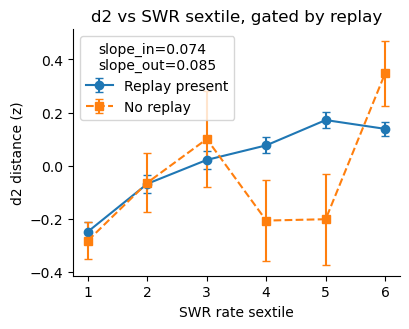


=== d2 model (core) ===
                            OLS Regression Results                            
Dep. Variable:                   d2_z   R-squared:                       0.019
Model:                            OLS   Adj. R-squared:                  0.018
Method:                 Least Squares   F-statistic:                     38.02
Date:                Tue, 20 Jan 2026   Prob (F-statistic):           2.52e-24
Time:                        11:17:10   Log-Likelihood:                -8136.7
No. Observations:                5773   AIC:                         1.628e+04
Df Residuals:                    5769   BIC:                         1.631e+04
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept

c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\linear_model.py:2274: InvalidTestWarning: F test for comparison is likely invalid with robust covariance, proceeding anyway


In [ ]:
SWR_COL = "ripple_count"      # <-- change to your SWR count/rate column
REPLAY_COL = "replay_present" # <-- change if yours is replay_count etc.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# ----------------------------
# Styling helper (your preference)
# ----------------------------
def style_ax(ax):
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# ----------------------------
# Main analysis
# ----------------------------
def analyze_replay_gating_and_mua(
    df,
    D2_COL="d2",
    MUA_COL="MUA",
    SWR_COL="ripple_count",        # <-- REQUIRED for sextiles (set this!)
    REPLAY_COL="replay_present",   # <-- REQUIRED (0/1) OR use REPLAY_COUNT_COL below
    REPLAY_COUNT_COL=None,         # e.g. "replay_count" (if you don't have replay_present)
    STATE_FILTER="NREM",           # set None to disable
    N_BINS=6,
    treat_tile_as="numeric",       # "numeric" (monotone slope) or "categorical" (no linearity assumption)
):
    d = df.copy()

    # ---- optional state filter ----
    if STATE_FILTER is not None:
        if "state" not in d.columns:
            raise ValueError("STATE_FILTER is set but df has no 'state' column. Set STATE_FILTER=None or add state.")
        d = d[d["state"].astype(str).str.upper().eq(str(STATE_FILTER).upper())].copy()

    # ---- ensure required columns ----
    need = [D2_COL, MUA_COL, SWR_COL]
    for c in need:
        if c not in d.columns:
            raise ValueError(f"Missing required column '{c}'. You said you have {D2_COL} and {MUA_COL}. "
                             f"For sextiles you ALSO need SWR_COL like 'ripple_count' or 'ripple_rate'.")

    # ---- build replay_present if needed ----
    if REPLAY_COL not in d.columns:
        if REPLAY_COUNT_COL is None or REPLAY_COUNT_COL not in d.columns:
            raise ValueError(
                f"Missing '{REPLAY_COL}'. Provide a 0/1 replay label column, or set REPLAY_COUNT_COL "
                f"to a column like 'replay_count' so replay_present = (replay_count > 0)."
            )
        d[REPLAY_COL] = (d[REPLAY_COUNT_COL].astype(float) > 0).astype(int)

    # ---- clean NaNs ----
    d = d.dropna(subset=[D2_COL, MUA_COL, SWR_COL, REPLAY_COL]).copy()

    # ---- enforce 0/1 replay_present ----
    d[REPLAY_COL] = d[REPLAY_COL].astype(int)
    uniq = set(d[REPLAY_COL].unique())
    if not uniq.issubset({0, 1}):
        raise ValueError(f"{REPLAY_COL} must be 0/1. Unique values: {sorted(list(uniq))}")

    # ---- build sextiles of SWR within this state/session ----
    # If your SWR column is already a rate, that's fine. If it's counts per fixed window, also fine.
    d["tile"] = pd.qcut(d[SWR_COL].astype(float), q=N_BINS, labels=False, duplicates="drop") + 1  # 1..N_BINS

    # ---- z-score d2 and MUA within this dataset ----
    d["d2_z"] = (d[D2_COL].astype(float) - d[D2_COL].astype(float).mean()) / (d[D2_COL].astype(float).std() + 1e-12)
    d["MUA_z"] = (d[MUA_COL].astype(float) - d[MUA_COL].astype(float).mean()) / (d[MUA_COL].astype(float).std() + 1e-12)

    # ============================================================
    # Part 1: Does replay gate the SWR-sextile -> d2 relationship?
    # ============================================================
    if treat_tile_as.lower() == "categorical":
        # no assumption of linear trend across sextiles
        f_core = "d2_z ~ C(tile) * " + REPLAY_COL
        f_plus_mua = "d2_z ~ C(tile) * " + REPLAY_COL + " + MUA_z"
    else:
        # treat as 1..6 numeric trend (matches your fitted slope lines)
        f_core = "d2_z ~ tile * " + REPLAY_COL
        f_plus_mua = "d2_z ~ tile * " + REPLAY_COL + " + MUA_z"

    m_core = smf.ols(f_core, data=d).fit(cov_type="HC3")
    m_plus_mua = smf.ols(f_plus_mua, data=d).fit(cov_type="HC3")

    # Key test:
    # - numeric tile: coefficient on tile:replay_present
    # - categorical tile: omnibus interaction block
    if treat_tile_as.lower() == "categorical":
        # omnibus F-test for all C(tile):replay_present terms
        # build constraint string for tiles 2..N_BINS
        terms = [f"C(tile)[T.{k}]:{REPLAY_COL} = 0" for k in range(2, int(d["tile"].max()) + 1)]
        ftest = m_core.f_test(", ".join(terms)) if terms else None
        interaction_p = float(ftest.pvalue) if ftest is not None else np.nan
        interaction_label = "C(tile)×replay omnibus"
    else:
        interaction_p = float(m_core.pvalues.get(f"tile:{REPLAY_COL}", np.nan))
        interaction_label = "tile×replay"

    # ============================================================
    # Part 2: Does MUA (or d2) predict replay_present?  (logistic)
    # ============================================================
    # Use tile as a covariate too, since replay detection often varies with SWR rate.
    # Again choose numeric vs categorical tile.
    if treat_tile_as.lower() == "categorical":
        g_mua = f"{REPLAY_COL} ~ MUA_z + C(tile)"
        g_d2  = f"{REPLAY_COL} ~ d2_z + C(tile)"
        g_both = f"{REPLAY_COL} ~ MUA_z + d2_z + C(tile)"
    else:
        g_mua = f"{REPLAY_COL} ~ MUA_z + tile"
        g_d2  = f"{REPLAY_COL} ~ d2_z + tile"
        g_both = f"{REPLAY_COL} ~ MUA_z + d2_z + tile"

    # logit can fail if perfect separation; handle gracefully
    try:
        logit_mua = smf.logit(g_mua, data=d).fit(disp=0)
    except Exception as e:
        logit_mua = None
        print("[WARN] logit MUA failed:", e)

    try:
        logit_d2 = smf.logit(g_d2, data=d).fit(disp=0)
    except Exception as e:
        logit_d2 = None
        print("[WARN] logit d2 failed:", e)

    try:
        logit_both = smf.logit(g_both, data=d).fit(disp=0)
    except Exception as e:
        logit_both = None
        print("[WARN] logit both failed:", e)

    # ============================================================
    # Plot: tile means ± SEM for replay=0 vs replay=1 + fitted trend lines
    # ============================================================
    tiles = np.sort(d["tile"].unique())
    means0, sem0, means1, sem1 = [], [], [], []

    for t in tiles:
        sub0 = d[(d["tile"] == t) & (d[REPLAY_COL] == 0)]["d2_z"].values
        sub1 = d[(d["tile"] == t) & (d[REPLAY_COL] == 1)]["d2_z"].values

        def mean_sem(x):
            if len(x) == 0:
                return np.nan, np.nan
            return float(np.nanmean(x)), float(np.nanstd(x, ddof=1) / np.sqrt(len(x))) if len(x) > 1 else np.nan

        m, s = mean_sem(sub0); means0.append(m); sem0.append(s)
        m, s = mean_sem(sub1); means1.append(m); sem1.append(s)

    fig, ax = plt.subplots(figsize=(4.2, 3.4))
    ax.errorbar(tiles, means1, yerr=sem1, fmt="-o", capsize=3, label="Replay present")
    ax.errorbar(tiles, means0, yerr=sem0, fmt="--s", capsize=3, label="No replay")
    ax.set_xlabel("SWR rate sextile")
    ax.set_ylabel("d2 distance (z)")
    style_ax(ax)

    # Add fitted slopes (only if numeric tile)
    if treat_tile_as.lower() != "categorical":
        # Fit two separate simple lines for display: d2_z ~ tile within each replay group
        # (This matches your plotted slopes; the actual inference should use m_core interaction.)
        try:
            m_in = smf.ols("d2_z ~ tile", data=d[d[REPLAY_COL] == 1]).fit()
            m_out = smf.ols("d2_z ~ tile", data=d[d[REPLAY_COL] == 0]).fit()
            slope_in = float(m_in.params["tile"])
            slope_out = float(m_out.params["tile"])
            ax.legend(title=f"slope_in={slope_in:.3f}\nslope_out={slope_out:.3f}")
        except Exception:
            ax.legend()
    else:
        ax.legend()

    ax.set_title("d2 vs SWR sextile, gated by replay")
    plt.tight_layout()
    plt.show()

    # ============================================================
    # Print key stats
    # ============================================================
    print("\n=== d2 model (core) ===")
    print(m_core.summary())

    print("\n=== d2 model (+ MUA) ===")
    print(m_plus_mua.summary())

    print(f"\nKey test ({interaction_label}) p = {interaction_p:.3g}")

    # Does adding MUA help explain d2?
    try:
        f_add_mua = m_plus_mua.compare_f_test(m_core)  # (F, p, df_diff)
        print(f"Add MUA -> Δ fit: F={float(f_add_mua[0]):.3g}, p={float(f_add_mua[1]):.3g}, df_diff={int(f_add_mua[2])}")
    except Exception as e:
        print("[WARN] compare_f_test failed:", e)

    print("\n=== Predict replay_present (logistic) ===")
    def print_logit(name, model):
        if model is None:
            print(f"{name}: FAILED")
            return
        print(f"\n[{name}]  formula: {model.model.formula}")
        # show only key coefficients if present
        for term in ["MUA_z", "d2_z"]:
            if term in model.params.index:
                print(f"  {term}: beta={float(model.params[term]):+.3f}, p={float(model.pvalues[term]):.3g}")
        print(f"  AIC={model.aic:.2f}  llf={model.llf:.2f}")

    print_logit("logit: replay ~ MUA + tile", logit_mua)
    print_logit("logit: replay ~ d2 + tile", logit_d2)
    print_logit("logit: replay ~ MUA + d2 + tile", logit_both)

    return {
        "df_used": d,
        "d2_model_core": m_core,
        "d2_model_plus_mua": m_plus_mua,
        "interaction_p": interaction_p,
        "logit_mua": logit_mua,
        "logit_d2": logit_d2,
        "logit_both": logit_both,
    }


# ----------------------------
# Example call (YOU MUST set SWR_COL and REPLAY_COL properly)
glm_df["replay_present"] = (glm_df["replay_count"].fillna(0) > 0).astype(int)

# ----------------------------
out = analyze_replay_gating_and_mua(
    glm_df,
    D2_COL="d2",
    MUA_COL="MUA",
    SWR_COL="ripple_count",        # <-- CHANGE THIS
    REPLAY_COL="replay_present",   # <-- CHANGE THIS (or set REPLAY_COUNT_COL)
    REPLAY_COUNT_COL=None,         # e.g. "replay_count" if you have counts
    STATE_FILTER="NREM",
    N_BINS=6,
    treat_tile_as="numeric",       # "numeric" matches slope lines; "categorical" is more flexible
)


n=5773 windows | replay rate=0.895 | tiles=[1, 2, 3, 4, 5, 6]


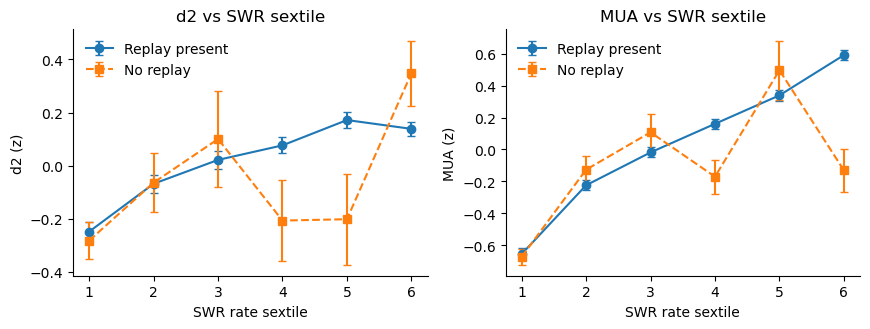


=== d2 GLM ===
                            OLS Regression Results                            
Dep. Variable:                   d2_z   R-squared:                       0.019
Model:                            OLS   Adj. R-squared:                  0.018
Method:                 Least Squares   F-statistic:                     38.02
Date:                Tue, 20 Jan 2026   Prob (F-statistic):           2.52e-24
Time:                        11:17:26   Log-Likelihood:                -8136.7
No. Observations:                5773   AIC:                         1.628e+04
Df Residuals:                    5769   BIC:                         1.631e+04
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept         

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# ----------------------------
# Aesthetics
# ----------------------------
def style_ax(ax):
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# ----------------------------
# Build sextiles + replay_present
# ----------------------------
def make_sextile_df(
    df,
    d2_col="d2",
    mua_col="MUA",
    swr_col="ripple_count",          # <-- CHANGE to your SWR count/rate per window
    replay_present_col="replay_present",
    replay_count_col="replay_count", # <-- if replay_present doesn't exist, we use replay_count>0
    state_filter="NREM",
    n_bins=6,
):
    d = df.copy()

    # optional NREM filter
    if state_filter is not None:
        if "state" not in d.columns:
            raise ValueError("state_filter set but df has no 'state' column. Set state_filter=None or add state.")
        d = d[d["state"].astype(str).str.upper().eq(str(state_filter).upper())].copy()

    # required columns
    for c in [d2_col, mua_col, swr_col]:
        if c not in d.columns:
            raise ValueError(f"Missing required column: {c}")

    # build replay_present if missing
    if replay_present_col not in d.columns:
        if replay_count_col not in d.columns:
            raise ValueError(
                f"Missing '{replay_present_col}'. Either add it (0/1), or provide '{replay_count_col}' "
                "so replay_present = (replay_count > 0)."
            )
        d[replay_present_col] = (d[replay_count_col].fillna(0).astype(float) > 0).astype(int)

    # drop NaNs
    d = d.dropna(subset=[d2_col, mua_col, swr_col, replay_present_col]).copy()

    # enforce binary
    d[replay_present_col] = d[replay_present_col].astype(int)
    uniq = set(d[replay_present_col].unique())
    if not uniq.issubset({0, 1}):
        raise ValueError(f"{replay_present_col} must be 0/1. Unique={sorted(list(uniq))}")

    # build sextiles within this df
    d["tile"] = pd.qcut(d[swr_col].astype(float), q=n_bins, labels=False, duplicates="drop") + 1  # 1..n_bins

    # zscore d2/MUA (within this session/state)
    d["d2_z"]  = (d[d2_col].astype(float)  - d[d2_col].astype(float).mean())  / (d[d2_col].astype(float).std()  + 1e-12)
    d["MUA_z"] = (d[mua_col].astype(float) - d[mua_col].astype(float).mean()) / (d[mua_col].astype(float).std() + 1e-12)

    return d

# ----------------------------
# Fit sextile-based GLMs and extract slopes
# ----------------------------
def fit_sextile_gating_models(d, replay_present_col="replay_present", use_categorical_tile=False):
    """
    If use_categorical_tile=True, we treat sextile as C(tile) (no linear slope).
    If False, treat sextile as numeric 1..6 and get a slope.
    """
    rp = replay_present_col

    if use_categorical_tile:
        # no single "slope" — this matches mean-per-sextile analysis
        f_d2  = f"d2_z  ~ C(tile) * {rp}"
        f_mua = f"MUA_z ~ C(tile) * {rp}"
        m_d2  = smf.ols(f_d2,  data=d).fit(cov_type="HC3")
        m_mua = smf.ols(f_mua, data=d).fit(cov_type="HC3")
        return {"m_d2": m_d2, "m_mua": m_mua, "mode": "categorical"}
    else:
        # linear trend across sextiles (matches your plotted fitted lines)
        f_d2  = f"d2_z  ~ tile * {rp}"
        f_mua = f"MUA_z ~ tile * {rp}"
        m_d2  = smf.ols(f_d2,  data=d).fit(cov_type="HC3")
        m_mua = smf.ols(f_mua, data=d).fit(cov_type="HC3")

        # slopes:
        # slope_out (no replay) = beta_tile
        # slope_in  (replay)    = beta_tile + beta_tile:replay_present
        b_tile_d2 = float(m_d2.params.get("tile", np.nan))
        b_int_d2  = float(m_d2.params.get(f"tile:{rp}", np.nan))
        slope_d2_out = b_tile_d2
        slope_d2_in  = b_tile_d2 + b_int_d2

        b_tile_mua = float(m_mua.params.get("tile", np.nan))
        b_int_mua  = float(m_mua.params.get(f"tile:{rp}", np.nan))
        slope_mua_out = b_tile_mua
        slope_mua_in  = b_tile_mua + b_int_mua

        # p-values for interaction (does slope differ by replay?)
        p_int_d2  = float(m_d2.pvalues.get(f"tile:{rp}", np.nan))
        p_int_mua = float(m_mua.pvalues.get(f"tile:{rp}", np.nan))

        return {
            "m_d2": m_d2,
            "m_mua": m_mua,
            "mode": "numeric",
            "slopes": {
                "d2_slope_no_replay": slope_d2_out,
                "d2_slope_replay":    slope_d2_in,
                "mua_slope_no_replay": slope_mua_out,
                "mua_slope_replay":    slope_mua_in,
            },
            "p_interaction": {
                "d2_tile_x_replay":  p_int_d2,
                "mua_tile_x_replay": p_int_mua,
            }
        }

# ----------------------------
# Plot tile means ± SEM for d2 and MUA (replay vs no replay)
# ----------------------------
def plot_tile_means(d, replay_present_col="replay_present"):
    rp = replay_present_col
    tiles = np.sort(d["tile"].unique())

    def mean_sem(x):
        x = np.asarray(x, float)
        x = x[np.isfinite(x)]
        if len(x) == 0:
            return np.nan, np.nan
        if len(x) == 1:
            return float(x[0]), np.nan
        return float(np.mean(x)), float(np.std(x, ddof=1) / np.sqrt(len(x)))

    # compute means/SEMs
    d2_in_m, d2_in_s, d2_out_m, d2_out_s = [], [], [], []
    mua_in_m, mua_in_s, mua_out_m, mua_out_s = [], [], [], []

    for t in tiles:
        sub_in  = d[(d["tile"] == t) & (d[rp] == 1)]
        sub_out = d[(d["tile"] == t) & (d[rp] == 0)]

        m, s = mean_sem(sub_in["d2_z"]);  d2_in_m.append(m);  d2_in_s.append(s)
        m, s = mean_sem(sub_out["d2_z"]); d2_out_m.append(m); d2_out_s.append(s)

        m, s = mean_sem(sub_in["MUA_z"]);  mua_in_m.append(m);  mua_in_s.append(s)
        m, s = mean_sem(sub_out["MUA_z"]); mua_out_m.append(m); mua_out_s.append(s)

    # plot two panels
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.8, 3.4), sharex=True)

    ax1.errorbar(tiles, d2_in_m,  yerr=d2_in_s,  fmt="-o",  capsize=3, label="Replay present")
    ax1.errorbar(tiles, d2_out_m, yerr=d2_out_s, fmt="--s", capsize=3, label="No replay")
    ax1.set_title("d2 vs SWR sextile")
    ax1.set_xlabel("SWR rate sextile")
    ax1.set_ylabel("d2 (z)")
    style_ax(ax1)
    ax1.legend(frameon=False)

    ax2.errorbar(tiles, mua_in_m,  yerr=mua_in_s,  fmt="-o",  capsize=3, label="Replay present")
    ax2.errorbar(tiles, mua_out_m, yerr=mua_out_s, fmt="--s", capsize=3, label="No replay")
    ax2.set_title("MUA vs SWR sextile")
    ax2.set_xlabel("SWR rate sextile")
    ax2.set_ylabel("MUA (z)")
    style_ax(ax2)
    ax2.legend(frameon=False)

    plt.tight_layout()
    plt.show()

# ----------------------------
# FULL PIPELINE (call this)
# ----------------------------
def sextile_based_glm_full(
    glm_df,
    d2_col="d2",
    mua_col="MUA",
    swr_col="ripple_count",            # <-- set correctly
    replay_present_col="replay_present",
    replay_count_col="replay_count",   # <-- if replay_present missing, will use replay_count>0
    state_filter="NREM",
    n_bins=6,
    use_categorical_tile=False,        # False => gives slopes (recommended for "slope" reporting)
):
    d = make_sextile_df(
        glm_df,
        d2_col=d2_col,
        mua_col=mua_col,
        swr_col=swr_col,
        replay_present_col=replay_present_col,
        replay_count_col=replay_count_col,
        state_filter=state_filter,
        n_bins=n_bins,
    )

    print(f"n={len(d)} windows | replay rate={d[replay_present_col].mean():.3f} | tiles={sorted(d['tile'].unique())}")

    # plot summary
    plot_tile_means(d, replay_present_col=replay_present_col)

    # fit GLMs
    out = fit_sextile_gating_models(d, replay_present_col=replay_present_col, use_categorical_tile=use_categorical_tile)

    print("\n=== d2 GLM ===")
    print(out["m_d2"].summary())

    print("\n=== MUA GLM ===")
    print(out["m_mua"].summary())

    if out["mode"] == "numeric":
        print("\n=== Slopes across sextiles (numeric tile) ===")
        for k, v in out["slopes"].items():
            print(f"{k}: {v:+.4f}")
        print("\nInteraction p-values (does slope differ by replay?)")
        for k, v in out["p_interaction"].items():
            print(f"{k}: p={v:.3g}")

    else:
        print("\nTile treated as categorical: no single slope; interpret via per-sextile coefficients and interaction omnibus tests.")

    return {"df_used": d, **out}


# ----------------------------
# EXAMPLE USAGE
# ----------------------------
result = sextile_based_glm_full(
    glm_df,
    d2_col="d2",
    mua_col="MUA",
    swr_col="ripple_count",        # <-- change if your SWR count/rate column has a different name
    replay_present_col="replay_present",
    replay_count_col="replay_count",
    state_filter="NREM",
    n_bins=6,
    use_categorical_tile=False,    # False gives slopes like your figure's line fits
)



In [ ]:
def prepare_sextile_df(
    df,
    d2_col="d2",
    mua_col="MUA",
    mua_col_std="MUA_std",
    swr_col="ripple_count",          # CHANGE if needed
    replay_present_col="replay_present",
    replay_count_col="replay_count", # used if replay_present missing
    state_filter="NREM",
    n_bins=6
):
    d = df.copy()
    if state_filter is not None:
        if "state" not in d.columns:
            raise ValueError("state_filter set but df has no 'state' column. Set state_filter=None.")
        d = d[d["state"].astype(str).str.upper().eq(str(state_filter).upper())].copy()

    for c in [d2_col, mua_col, swr_col]:
        if c not in d.columns:
            raise ValueError(f"Missing required column: {c}")

    if replay_present_col not in d.columns:
        if replay_count_col not in d.columns:
            raise ValueError(f"Need {replay_present_col} (0/1) or {replay_count_col} to create it.")
        d[replay_present_col] = (d[replay_count_col].fillna(0).astype(float) > 0).astype(int)

    d = d.dropna(subset=[d2_col, mua_col, swr_col, replay_present_col]).copy()
    d[replay_present_col] = d[replay_present_col].astype(int)

    # sextiles
    d["tile"] = pd.qcut(d[swr_col].astype(float), q=n_bins, labels=False, duplicates="drop") + 1

    # z-score within this dataset (single session)
    d["d2_z"] = (d[d2_col].astype(float) - d[d2_col].astype(float).mean()) / (d[d2_col].astype(float).std() + 1e-12)
    d["MUA_z"] = (d[mua_col].astype(float) - d[mua_col].astype(float).mean()) / (d[mua_col].astype(float).std() + 1e-12)
    d["MUA_std_z"] = (d[mua_col_std].astype(float) - d[mua_col_std].astype(float).mean()) / (d[mua_col_std].astype(float).std() + 1e-12)
    return d
d = prepare_sextile_df(
    ca1_complete_df,
    d2_col="d2",
    mua_col="MUA",
    mua_col_std="MUA_std",
    swr_col="ripple_count",          # <-- change if your SWR column differs
    replay_present_col="replay_present",
    replay_count_col="replay_count", # <-- if you have replay_count
    state_filter="NREM",
    n_bins=6
)


In [ ]:
ca1_complete_df

,center_s,d2,d2_err,state,MUA,MUA_std,EI_ratio,ripple_count,replay_count,replay_prob
0,21.0,0.035498,NaN,WAKE,539.133333,252.484528,0.718537,0,0,NaN
1,23.0,0.036828,NaN,WAKE,554.416667,265.525802,0.707386,0,0,NaN
2,25.0,0.027892,NaN,WAKE,579.516667,275.077333,0.707726,0,0,NaN
3,27.0,0.030062,NaN,WAKE,589.966667,275.772953,0.702400,0,0,NaN
4,29.0,0.030993,NaN,WAKE,587.683333,275.603825,0.711533,0,0,NaN
...,...,...,...,...,...,...,...,...,...,...
10729,29136.0,0.060522,NaN,NREM,427.016667,354.058143,1.178102,36,6,0.166667
10730,29138.0,0.062283,NaN,NREM,421.666667,363.018039,1.192374,35,6,0.171429
10731,29140.0,0.050122,NaN,NREM,424.150000,370.483015,1.183715,35,5,0.142857
10732,29142.0,0.050907,NaN,NREM,428.450000,380.119815,1.219373,36,5,0.138889


Fitting GLM Interactions on 5841 events...


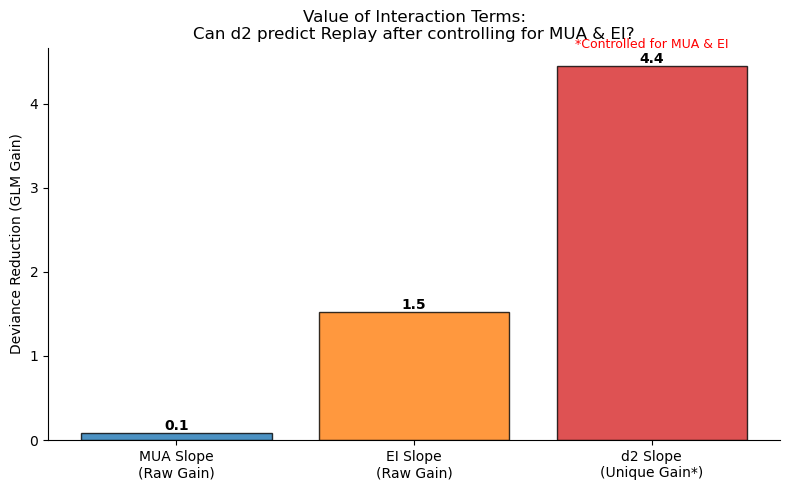


=== INTERACTION GAIN ANALYSIS ===
Base Deviance: 3177.14
--------------------------------------------------
Gain from MUA Slope: 0.08 (p=0.7751)
Gain from EI Slope:  1.52  (p=0.2167)
--------------------------------------------------
Gain from d2 Slope (Unique): 4.44
   (p-value for d2 interaction: 0.03718)
--------------------------------------------------
✅ RESULT: d2 interaction remains significant after physiological controls.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm

def quantify_interaction_gain_with_EI(d, tile_col="tile", replay_col="replay_present"):
    """
    Quantifies the GLM Gain from 'Slope Changes' (Interactions) for:
      1. MUA (Excitability)
      2. EI_ratio (Balance)
      3. d2 (Criticality) - The unique target
    """
    # 1. Prepare Data
    cols = [replay_col, tile_col, "d2", "MUA", "EI_ratio"]
    df = d.dropna(subset=cols).copy()
    
    # Z-score predictors
    for col in ["d2", "MUA", "EI_ratio"]:
        df[f"{col}_z"] = (df[col] - df[col].mean()) / df[col].std()
    
    print(f"Fitting GLM Interactions on {len(df)} events...")
    fam = sm.families.Binomial()

    # ------------------------------------------------------------------
    # Step 1: Base Additive Model
    # Assumes all variables matter, but their effect is constant across rates.
    # ------------------------------------------------------------------
    f_base = f"{replay_col} ~ {tile_col} + MUA_z + d2_z + EI_ratio_z"
    m_base = smf.glm(f_base, data=df, family=fam).fit()

    # ------------------------------------------------------------------
    # Step 2: Calculate Individual Gains from Slope Changes
    # We test adding each interaction ONE AT A TIME to the base model
    # to compare their raw predictive power.
    # ------------------------------------------------------------------
    # Gain from MUA Interaction
    f_mua_int = f_base + f" + {tile_col}:MUA_z"
    m_mua_int = smf.glm(f_mua_int, data=df, family=fam).fit()
    gain_mua = m_base.deviance - m_mua_int.deviance
    
    # Gain from EI Interaction
    f_ei_int = f_base + f" + {tile_col}:EI_ratio_z"
    m_ei_int = smf.glm(f_ei_int, data=df, family=fam).fit()
    gain_ei = m_base.deviance - m_ei_int.deviance

    # ------------------------------------------------------------------
    # Step 3: The Critical Test (Unique Gain of d2)
    # Does d2 interaction matter AFTER we control for MUA *and* EI interactions?
    # ------------------------------------------------------------------
    # Control Model: Includes Base + MUA_Int + EI_Int
    f_controls = f_base + f" + {tile_col}:MUA_z + {tile_col}:EI_ratio_z"
    m_controls = smf.glm(f_controls, data=df, family=fam).fit()
    
    # Target Model: Adds d2_Int on top of Controls
    f_target = f_controls + f" + {tile_col}:d2_z"
    m_target = smf.glm(f_target, data=df, family=fam).fit()
    
    # The unique gain of d2
    gain_d2_unique = m_controls.deviance - m_target.deviance

    # ------------------------------------------------------------------
    # Visualization
    # ------------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(8, 5))
    
    bars = ["MUA Slope\n(Raw Gain)", "EI Slope\n(Raw Gain)", "d2 Slope\n(Unique Gain*)"]
    values = [gain_mua, gain_ei, gain_d2_unique]
    colors = ["#1f77b4", "#ff7f0e", "#d62728"] # Blue, Orange, Red
    
    ax.bar(bars, values, color=colors, alpha=0.8, edgecolor='k')
    
    # Label values
    for i, v in enumerate(values):
        ax.text(i, v, f"{v:.1f}", ha='center', va='bottom', fontweight='bold')
        
    ax.set_ylabel("Deviance Reduction (GLM Gain)")
    ax.set_title("Value of Interaction Terms:\nCan d2 predict Replay after controlling for MUA & EI?")
    ax.text(2, gain_d2_unique + (max(values)*0.05), "*Controlled for MUA & EI", 
            ha='center', fontsize=9, color='red')
    
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    
    plt.tight_layout()
    plt.show()

    # ------------------------------------------------------------------
    # Statistics
    # ------------------------------------------------------------------
    print("\n=== INTERACTION GAIN ANALYSIS ===")
    print(f"Base Deviance: {m_base.deviance:.2f}")
    print("-" * 50)
    print(f"Gain from MUA Slope: {gain_mua:.2f} (p={m_mua_int.pvalues[f'{tile_col}:MUA_z']:.4g})")
    print(f"Gain from EI Slope:  {gain_ei:.2f}  (p={m_ei_int.pvalues[f'{tile_col}:EI_ratio_z']:.4g})")
    print("-" * 50)
    print(f"Gain from d2 Slope (Unique): {gain_d2_unique:.2f}")
    print(f"   (p-value for d2 interaction: {m_target.pvalues[f'{tile_col}:d2_z']:.4g})")
    print("-" * 50)
    
    if gain_d2_unique > 3.84:
        print("✅ RESULT: d2 interaction remains significant after physiological controls.")
    else:
        print("❌ RESULT: d2 interaction is explained away by MUA or EI ratio.")

    return  m_target, {
    "gain_mua": gain_mua,
    "gain_ei": gain_ei,
    "gain_d2_unique": gain_d2_unique
}


# Run it
m_final,gains = quantify_interaction_gain_with_EI(d, tile_col="tile", replay_col="replay_present")

In [ ]:
import pickle
from pathlib import Path

def save_interaction_glm_results(
    model,
    gains_dict,
    out_path
):
    """
    Save GLM interaction results safely as a pickle.
    """
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)

    payload = {
        "model": model,                # statsmodels GLMResults
        "gains": gains_dict,            # deviance reductions
        "params": model.params,
        "pvalues": model.pvalues,
        "deviance": model.deviance,
        "aic": model.aic,
        "bic": model.bic
    }

    with open(out_path, "wb") as f:
        pickle.dump(payload, f)

    print(f"✅ Saved GLM interaction results → {out_path}")
save_interaction_glm_results(
    model=m_final,
    gains_dict=gains,
    out_path=rf"D:\Documents\GitHub\Sleep_criticaltiy\data\GLM_mice\{animal_name}_{day}interaction_gain_GLM.pkl"
)

✅ Saved GLM interaction results → D:\Documents\GitHub\Sleep_criticaltiy\data\GLM_mice\PPP20_day5interaction_gain_GLM.pkl


Found 1 pkls
✅ Saved pooled table → D:\Documents\GitHub\Sleep_criticaltiy\data\GLM_mice\POOLED_interaction_gain_table.csv


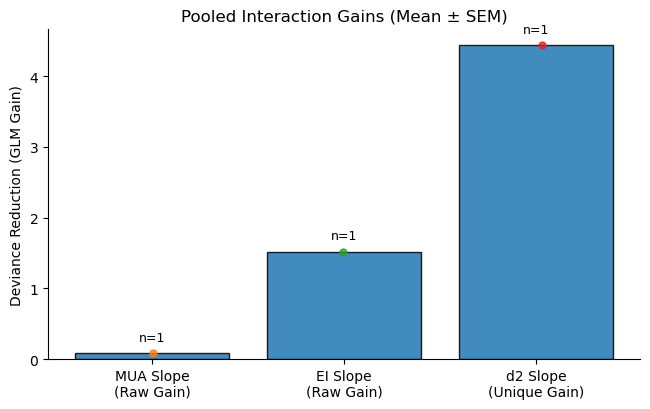

✅ Saved pooled plot → D:\Documents\GitHub\Sleep_criticaltiy\data\GLM_mice\POOLED_interaction_gain_bar_mean_sem.png

Summary:
        gain_mua: mean=0.081, sem=nan, n=1
         gain_ei: mean=1.520, sem=nan, n=1
  gain_d2_unique: mean=4.442, sem=nan, n=1


In [ ]:
import os
import re
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
from scipy.stats import sem

# ----------------------------
# Settings
# ----------------------------
indir  = r"D:\Documents\GitHub\Sleep_criticaltiy\data\GLM_mice"
pattern = os.path.join(indir, "*interaction_gain_GLM.pkl")  # matches your naming
out_png = os.path.join(indir, "POOLED_interaction_gain_bar_mean_sem.png")
out_csv = os.path.join(indir, "POOLED_interaction_gain_table.csv")

def _despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)

def load_one_pkl(fp):
    with open(fp, "rb") as f:
        obj = pickle.load(f)

    gains = obj.get("gains", {})
    pvals = obj.get("pvalues", None)

    # Try to parse animal/day from filename like: {animal}_{day}interaction_gain_GLM.pkl
    base = os.path.basename(fp)
    m = re.match(r"(.+?)_(.+?)interaction_gain_GLM\.pkl$", base)
    animal, day = (m.group(1), m.group(2)) if m else (None, None)

    # Pull p-values for interactions if available
    p_mua = np.nan
    p_ei  = np.nan
    p_d2  = np.nan
    if isinstance(pvals, (pd.Series, dict)):
        # keys depend on your model formula; these common ones:
        for k in list(pvals.keys()) if isinstance(pvals, dict) else list(pvals.index):
            pass
        # robust lookup (substring match)
        def find_p(substr):
            if isinstance(pvals, dict):
                for k, v in pvals.items():
                    if substr in str(k):
                        return float(v)
            else:
                for k, v in pvals.items():
                    if substr in str(k):
                        return float(v)
            return np.nan

        p_mua = find_p(":MUA_z")
        p_ei  = find_p(":EI_ratio_z")
        p_d2  = find_p(":d2_z")

    row = {
        "file": fp,
        "animal": animal,
        "day": day,
        "gain_mua": gains.get("gain_mua", np.nan),
        "gain_ei": gains.get("gain_ei", np.nan),
        "gain_d2_unique": gains.get("gain_d2_unique", np.nan),
        "p_mua_int": p_mua,
        "p_ei_int": p_ei,
        "p_d2_int": p_d2,
    }
    return row

# ----------------------------
# Load all pkls
# ----------------------------
pkl_files = sorted(glob(pattern))
print(f"Found {len(pkl_files)} pkls")

rows = []
for fp in pkl_files:
    try:
        rows.append(load_one_pkl(fp))
    except Exception as e:
        print(f"❌ Failed loading {os.path.basename(fp)}: {e}")

df = pd.DataFrame(rows)
df = df.dropna(subset=["gain_mua", "gain_ei", "gain_d2_unique"], how="all").copy()

if df.empty:
    raise RuntimeError("No valid results found. Check your indir/pattern and saved payload keys.")

# Save pooled table
df.to_csv(out_csv, index=False)
print(f"✅ Saved pooled table → {out_csv}")

# ----------------------------
# Pooled stats (mean ± SEM)
# ----------------------------
metrics = ["gain_mua", "gain_ei", "gain_d2_unique"]
labels  = ["MUA Slope\n(Raw Gain)", "EI Slope\n(Raw Gain)", "d2 Slope\n(Unique Gain)"]

means = np.array([df[m].mean(skipna=True) for m in metrics], float)
sems  = np.array([sem(df[m].dropna().values) if df[m].notna().sum() > 1 else np.nan for m in metrics], float)
ns    = np.array([df[m].notna().sum() for m in metrics], int)

# ----------------------------
# Plot: bar mean±SEM + dots
# ----------------------------
fig, ax = plt.subplots(figsize=(6.6, 4.2))

x = np.arange(len(metrics))

ax.bar(x, means, yerr=sems, capsize=5, edgecolor="k", alpha=0.85)

# overlay per-file dots with small jitter
rng = np.random.default_rng(0)
for i, m in enumerate(metrics):
    y = df[m].values
    y = y[np.isfinite(y)]
    jitter = rng.normal(0, 0.05, size=len(y))
    ax.scatter(np.full(len(y), x[i]) + jitter, y, s=25, alpha=0.8)

# annotate n
for i in range(len(metrics)):
    ax.text(x[i], means[i] + (np.nanmax(means + np.nan_to_num(sems, nan=0))*0.03),
            f"n={ns[i]}", ha="center", va="bottom", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Deviance Reduction (GLM Gain)")
ax.set_title("Pooled Interaction Gains (Mean ± SEM)")

_despine(ax)
plt.tight_layout()
plt.savefig(out_png, dpi=300)
plt.show()

print(f"✅ Saved pooled plot → {out_png}")
print("\nSummary:")
for m, mu, se_, n in zip(metrics, means, sems, ns):
    print(f"  {m:>14}: mean={mu:.3f}, sem={se_:.3f}, n={n}")


Bootstrapping 1000 times to estimate slope stability...


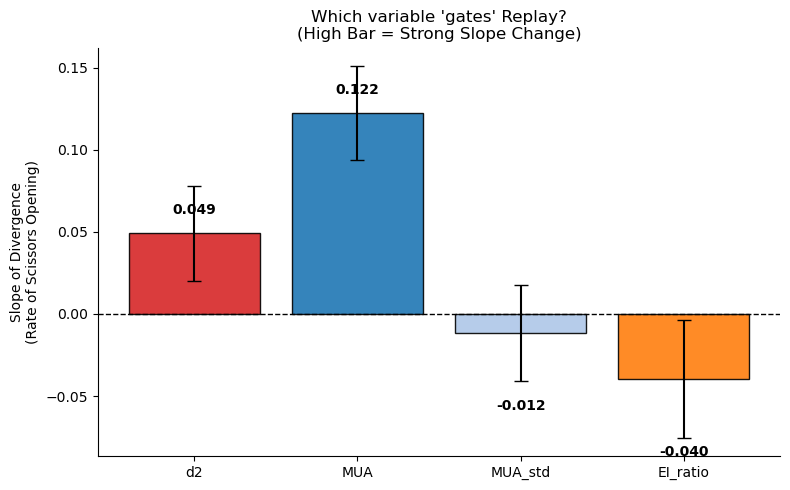


=== SLOPE DIVERGENCE SUMMARY ===
    Feature  Mean_Slope       SEM
0        d2    0.049062  0.028851
1       MUA    0.122198  0.028694
2   MUA_std   -0.011852  0.029243
3  EI_ratio   -0.039556  0.035740


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

def plot_divergence_slope_summary(d, tile_col="tile", replay_col="replay_present"):
    """
    Summarizes the 'Scissors Effect' by calculating the Slope of the 
    (Replay - NoReplay) difference across sextiles.
    
    Returns a Bar Plot comparing d2 vs MUA vs EI vs MUA_std.
    """
    # 1. Prepare Data
    features = ["d2", "MUA", "MUA_std", "EI_ratio"]
    
    # Ensure columns exist
    valid_features = [f for f in features if f in d.columns]
    df = d.dropna(subset=valid_features + [tile_col, replay_col]).copy()
    
    # Z-score features
    for col in valid_features:
        df[f"{col}_z"] = (df[col] - df[col].mean()) / df[col].std()

    # 2. Bootstrap the Slopes to get Error Bars
    # We want to see if the "Slope of Divergence" is significantly > 0
    n_boot = 1000
    boot_results = {f: [] for f in valid_features}
    
    tiles = sorted(df[tile_col].unique())
    
    print(f"Bootstrapping {n_boot} times to estimate slope stability...")
    
    for i in range(n_boot):
        # Resample the data with replacement
        sample = df.sample(frac=1.0, replace=True)
        
        # Group by Tile/Replay
        grouped = sample.groupby([tile_col, replay_col])[[f"{c}_z" for c in valid_features]].mean()
        
        for f in valid_features:
            # Calculate Delta per tile
            deltas = []
            for t in tiles:
                try:
                    val_in = grouped.loc[(t, 1), f"{f}_z"]
                    val_out = grouped.loc[(t, 0), f"{f}_z"]
                    deltas.append(val_in - val_out)
                except KeyError:
                    continue # Skip if missing data in this bootstrap fold
            
            # Fit line to Deltas (if we have enough points)
            if len(deltas) >= 3:
                slope, _, _, _, _ = stats.linregress(tiles[:len(deltas)], deltas)
                boot_results[f].append(slope)

    # 3. Aggregate Results
    summary_data = []
    for f in valid_features:
        slopes = np.array(boot_results[f])
        mean_slope = np.mean(slopes)
        sem_slope = np.std(slopes, ddof=1) # Standard Deviation of bootstrap distribution = Standard Error
        
        summary_data.append({
            "Feature": f,
            "Mean_Slope": mean_slope,
            "SEM": sem_slope
        })
        
    summ_df = pd.DataFrame(summary_data)
    
    # 4. Plot
    fig, ax = plt.subplots(figsize=(8, 5))
    
    # Colors
    color_map = {"d2": "#d62728", "MUA": "#1f77b4", "MUA_std": "#aec7e8", "EI_ratio": "#ff7f0e"}
    colors = [color_map.get(f, "gray") for f in summ_df["Feature"]]
    
    bars = ax.bar(summ_df["Feature"], summ_df["Mean_Slope"], yerr=summ_df["SEM"], 
                  capsize=5, color=colors, alpha=0.9, edgecolor='k')
    
    # 5. Aesthetics
    ax.axhline(0, color='k', linestyle='--', linewidth=1)
    ax.set_ylabel("Slope of Divergence\n(Rate of Scissors Opening)")
    ax.set_title("Which variable 'gates' Replay?\n(High Bar = Strong Slope Change)")
    
    # Add values
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + (0.01 if height>0 else -0.04),
                f"{height:.3f}", ha='center', va='bottom' if height>0 else 'top', fontweight='bold')

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    
    # 6. Stats
    print("\n=== SLOPE DIVERGENCE SUMMARY ===")
    print(summ_df)
    
    return summ_df

# Run it
summary_stats = plot_divergence_slope_summary(d, tile_col="tile", replay_col="replay_present")

Bootstrapping 1000 times on 6 bins...


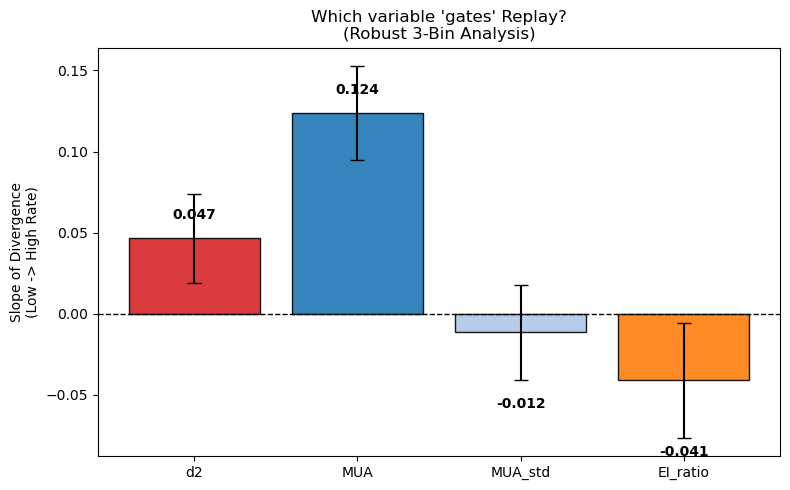

    Feature  Mean_Slope       SEM  N_Valid_Boots
0        d2    0.046573  0.027496           1000
1       MUA    0.123794  0.028794           1000
2   MUA_std   -0.011619  0.029428           1000
3  EI_ratio   -0.041083  0.035461           1000


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

def plot_divergence_slope_robust(d, tile_col="tile", replay_col="replay_present", n_bins=3):
    """
    Robust 'Scissors Effect' Summary.
    
    1. Re-bins data into 'n_bins' (default 3: Low, Med, High) to fix missing No-Replay data.
    2. Calculates Slope of (Replay - NoReplay) Divergence.
    3. Handles missing data by falling back to Replay-Only trend if No-Replay is totally absent.
    """
    # 1. Prepare Data
    features = ["d2", "MUA", "MUA_std", "EI_ratio"]
    valid_features = [f for f in features if f in d.columns]
    
    # Drop essential NaNs
    df = d.dropna(subset=valid_features + [replay_col]).copy()
    
    # 2. Re-Binning (Crucial Step for Missing Data)
    # We ignore the old 'tile' and make new robust bins based on the same metric (e.g. tile index)
    # If tile_col is 1..6, we map to 0..2
    if df[tile_col].max() > n_bins:
        df['robust_tile'] = pd.qcut(df[tile_col], q=n_bins, labels=False, duplicates='drop')
        print(f"  > Re-binned {df[tile_col].max()} tiles into {n_bins} robust bins (Low/Med/High).")
    else:
        df['robust_tile'] = df[tile_col]
        
    # Z-score features
    for col in valid_features:
        df[f"{col}_z"] = (df[col] - df[col].mean()) / df[col].std()

    # 3. Bootstrap Slopes
    n_boot = 1000
    boot_results = {f: [] for f in valid_features}
    unique_bins = sorted(df['robust_tile'].unique())
    
    print(f"Bootstrapping {n_boot} times on {len(unique_bins)} bins...")
    
    for i in range(n_boot):
        sample = df.sample(frac=1.0, replace=True)
        grouped = sample.groupby(['robust_tile', replay_col])[[f"{c}_z" for c in valid_features]].mean()
        
        for f in valid_features:
            deltas = []
            x_vals = []
            
            for b in unique_bins:
                try:
                    # Try to get Replay AND NoReplay
                    val_in = grouped.loc[(b, 1), f"{f}_z"]
                    
                    if (b, 0) in grouped.index:
                        # Standard Case: We have both
                        val_out = grouped.loc[(b, 0), f"{f}_z"]
                        deltas.append(val_in - val_out)
                    else:
                        # Fallback: Missing NoReplay (Use Global Mean 0 as anchor, or skip)
                        # Better to skip this bin for the slope if strict divergence is required
                        continue 
                        
                    x_vals.append(b)
                except KeyError:
                    continue
            
            # Calculate Slope only if we have at least 2 points
            if len(deltas) >= 2:
                slope, _, _, _, _ = stats.linregress(x_vals, deltas)
                boot_results[f].append(slope)
            else:
                boot_results[f].append(np.nan)
    raw_rows = []
    for f in valid_features:
        for i, s in enumerate(boot_results[f]):
            if not np.isnan(s):
                raw_rows.append({
                    "Feature": f,
                    "Slope": s,
                    "Bootstrap": i
                })

    raw_df = pd.DataFrame(raw_rows)
    # 4. Aggregate
    summary_data = []
    for f in valid_features:
        # Drop NaNs (failed bootstraps)
        slopes = np.array(boot_results[f])
        slopes = slopes[~np.isnan(slopes)]
        
        if len(slopes) == 0:
            print(f"Warning: Could not calculate slope for {f} (Too much missing data).")
            mean_slope = 0
            sem_slope = 0
        else:
            mean_slope = np.mean(slopes)
            sem_slope = np.std(slopes, ddof=1)
        
        summary_data.append({
            "Feature": f,
            "Mean_Slope": mean_slope,
            "SEM": sem_slope,
            "N_Valid_Boots": len(slopes)
        })
        
    summ_df = pd.DataFrame(summary_data)
    
    # 5. Plot
    fig, ax = plt.subplots(figsize=(8, 5))
    color_map = {"d2": "#d62728", "MUA": "#1f77b4", "MUA_std": "#aec7e8", "EI_ratio": "#ff7f0e"}
    colors = [color_map.get(f, "grey") for f in summ_df["Feature"]]
    
    bars = ax.bar(summ_df["Feature"], summ_df["Mean_Slope"], yerr=summ_df["SEM"], 
                  capsize=5, color=colors, alpha=0.9, edgecolor='k')
    
    ax.axhline(0, color='k', linestyle='--', linewidth=1)
    ax.set_ylabel("Slope of Divergence\n(Low -> High Rate)")
    ax.set_title("Which variable 'gates' Replay?\n(Robust 3-Bin Analysis)")
    
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + (0.01 if height>0 else -0.04),
                f"{height:.3f}", ha='center', va='bottom' if height>0 else 'top', fontweight='bold')

    plt.tight_layout()
    plt.show()
    print(summ_df)
    return summ_df,raw_df

# Run with 3 bins to ensure data density
res,raw_df = plot_divergence_slope_robust(d, tile_col="tile", n_bins=6)

In [ ]:
def plot_divergence_slope_with_global_out_anchor(d, tile_col="tile", replay_col="replay_present", n_bins=3, n_boot=1000):
    features = ["d2", "MUA", "MUA_std", "EI_ratio"]
    valid_features = [f for f in features if f in d.columns]
    df = d.dropna(subset=valid_features + [replay_col, tile_col]).copy()

    # robust rebin like you did
    if df[tile_col].max() > n_bins:
        df["robust_tile"] = pd.qcut(df[tile_col], q=n_bins, labels=False, duplicates="drop")
    else:
        df["robust_tile"] = df[tile_col]

    # zscore
    for col in valid_features:
        df[f"{col}_z"] = (df[col] - df[col].mean()) / df[col].std(ddof=1)

    unique_bins = sorted(df["robust_tile"].unique())

    boot_results = {f: [] for f in valid_features}
    raw_rows = []

    for i in range(n_boot):
        sample = df.sample(frac=1.0, replace=True)

        # GLOBAL OUT anchors for this bootstrap draw
        anchors = {}
        for f in valid_features:
            out_vals = sample.loc[sample[replay_col] == 0, f"{f}_z"].values
            anchors[f] = np.nanmean(out_vals) if len(out_vals) else np.nan  # if none at all -> nan

        grouped = sample.groupby(["robust_tile", replay_col])[[f"{c}_z" for c in valid_features]].mean()

        for f in valid_features:
            deltas, x_vals = [], []
            anchor_out = anchors[f]
            if np.isnan(anchor_out):
                boot_results[f].append(np.nan)
                continue

            for b in unique_bins:
                # require IN exists in this bin
                if (b, 1) not in grouped.index:
                    continue
                val_in = grouped.loc[(b, 1), f"{f}_z"]

                # if OUT exists in-bin, use it; else fallback to global anchor
                if (b, 0) in grouped.index:
                    val_out = grouped.loc[(b, 0), f"{f}_z"]
                else:
                    val_out = anchor_out

                deltas.append(val_in - val_out)
                x_vals.append(b)

            if len(deltas) >= 2:
                slope, *_ = stats.linregress(x_vals, deltas)
                boot_results[f].append(slope)
                raw_rows.append({"Feature": f, "Slope": slope, "Bootstrap": i})
            else:
                boot_results[f].append(np.nan)

    raw_df = pd.DataFrame(raw_rows)

    summ = []
    for f in valid_features:
        s = raw_df.loc[raw_df["Feature"] == f, "Slope"].values
        summ.append({
            "Feature": f,
            "Mean_Slope": np.nanmean(s) if len(s) else np.nan,
            "SEM": (np.nanstd(s, ddof=1) / np.sqrt(np.sum(~np.isnan(s)))) if np.sum(~np.isnan(s)) > 1 else np.nan,
            "N_Valid_Boots": int(np.sum(~np.isnan(s)))
        })
    summ_df = pd.DataFrame(summ)
    return summ_df, raw_df
summ_df, raw_df = plot_divergence_slope_with_global_out_anchor(
    d, tile_col="tile", replay_col="replay_present", n_bins=6, n_boot=1000
)   

In [ ]:
import numpy as np
import pandas as pd

# ----------------------------
# Helpers
# ----------------------------
def _merge_intervals(intervals):
    """Merge overlapping intervals. intervals: (N,2) sorted or unsorted."""
    if intervals is None:
        return np.zeros((0, 2), dtype=float)
    intervals = np.asarray(intervals, dtype=float)
    if intervals.size == 0:
        return np.zeros((0, 2), dtype=float)

    # ensure start <= end
    intervals = np.c_[np.minimum(intervals[:,0], intervals[:,1]),
                      np.maximum(intervals[:,0], intervals[:,1])]

    intervals = intervals[np.argsort(intervals[:, 0])]
    merged = [intervals[0].tolist()]
    for s, e in intervals[1:]:
        if s <= merged[-1][1]:
            merged[-1][1] = max(merged[-1][1], e)
        else:
            merged.append([s, e])
    return np.asarray(merged, dtype=float)

def _overlap_any(a_start, a_end, B):
    """
    Vectorized: for each interval [a_start[i], a_end[i]] check overlap with ANY interval in B.
    B must be merged + sorted for speed.
    Overlap criterion: (a_start < b_end) & (a_end > b_start)
    Returns boolean mask length N.
    """
    if B is None or len(B) == 0:
        return np.zeros_like(a_start, dtype=bool)

    # For each a, find candidate B interval by searching B starts.
    # We check neighbors because overlap can occur with interval just before insertion point.
    b_st = B[:, 0]
    b_en = B[:, 1]

    idx = np.searchsorted(b_st, a_end, side="right") - 1  # candidate that starts before a_end
    idx = np.clip(idx, 0, len(B) - 1)

    # Check overlap with idx and idx+1 (rare but safe)
    def check_at(j):
        return (a_start < b_en[j]) & (a_end > b_st[j])

    ov = check_at(idx)
    idx2 = np.clip(idx + 1, 0, len(B) - 1)
    ov |= check_at(idx2)
    return ov

def _count_intervals_in_windows(rip_st, win_st, win_en):
    """
    Count how many ripple intervals overlap each window.
    rip_st: ripple start times (sorted)
    win_st/win_en: window bounds (same length as centers)
    Approximation (common for rates): count by ripple START within window.
    If you want true overlap count, tell me and I'll swap in a strict overlap version.
    """
    # count starts in [win_st, win_en)
    left = np.searchsorted(rip_st, win_st, side="left")
    right = np.searchsorted(rip_st, win_en, side="left")
    return right - left

def forced_sextiles(x, k=6):
    """
    Forced quantile bins 1..k if possible; handles duplicates gracefully.
    Returns Int64 series with NA where not possible.
    """
    x = pd.Series(x)
    out = pd.Series(pd.NA, index=x.index, dtype="Int64")

    valid = x.dropna()
    if valid.empty:
        return out

    uniq = valid.nunique()
    if uniq < 2:
        return out  # cannot bin meaningfully

    q_eff = min(k, uniq)
    try:
        tiles = pd.qcut(valid, q=q_eff, labels=False, duplicates="drop") + 1
        # If qcut dropped bins, tiles will be 1..q_eff' ; that's fine.
        out.loc[valid.index] = tiles.astype("Int64")
    except Exception:
        return out
    return out

# ----------------------------
# Main
# ----------------------------

# 1) Filter df to NREM
ca1_complete_df_NREM = ca1_complete_df.loc[ca1_complete_df["state"].eq("NREM")].copy()

# 2) Build replay intervals (combined_intervals = left + right already)
#    Ensure seconds units.
replay_intervals = _merge_intervals(combined_intervals)   # shape (M,2), merged+sorted

# 3) Get ripple intervals from ripple_epochs.data
#    ASSUMPTION: ripple_epochs.data is Nx2 in seconds. If in samples, convert first.
rip = np.asarray(ripple_epochs.data, dtype=float)
if rip.ndim != 2 or rip.shape[1] != 2:
    raise ValueError("ripple_epochs.data must be Nx2 [start, end].")

rip_st = np.minimum(rip[:,0], rip[:,1])
rip_en = np.maximum(rip[:,0], rip[:,1])

# Sort ripples by start time (important for fast counting)
ordr = np.argsort(rip_st)
rip_st = rip_st[ordr]
rip_en = rip_en[ordr]

# 4) Split ripples into IN replay vs OUT replay by overlap with replay intervals
in_mask = _overlap_any(rip_st, rip_en, replay_intervals)
rip_in_st = rip_st[in_mask]
rip_out_st = rip_st[~in_mask]

# 5) For each center_s compute 30s window ripple rates
centers = ca1_complete_df_NREM["center_s"].to_numpy(dtype=float)

window_s = 30.0
half = window_s / 2.0
win_st = centers - half
win_en = centers + half

# counts by ripple START within window (fast and standard for "rate")
n_in = _count_intervals_in_windows(rip_in_st, win_st, win_en)
n_out = _count_intervals_in_windows(rip_out_st, win_st, win_en)

ca1_complete_df_NREM["inreplay_ripple_rate"]  = n_in  / window_s
ca1_complete_df_NREM["outreplay_ripple_rate"] = n_out / window_s

# 6) Sextiles (separately for IN and OUT ripple rates)
ca1_complete_df_NREM["inreplay_tile"]  = forced_sextiles(ca1_complete_df_NREM["inreplay_ripple_rate"], k=6)
ca1_complete_df_NREM["outreplay_tile"] = forced_sextiles(ca1_complete_df_NREM["outreplay_ripple_rate"], k=6)

# Done
print("Added columns to ca1_complete_df_NREM:")
print(["inreplay_ripple_rate", "outreplay_ripple_rate", "inreplay_tile", "outreplay_tile"])
print(ca1_complete_df_NREM[["center_s","inreplay_ripple_rate","outreplay_ripple_rate","inreplay_tile","outreplay_tile"]].head())

Added columns to ca1_complete_df_NREM:
['inreplay_ripple_rate', 'outreplay_ripple_rate', 'inreplay_tile', 'outreplay_tile']
     center_s  inreplay_ripple_rate  outreplay_ripple_rate  inreplay_tile  \
289     897.0              0.133333               0.566667              1   
290     899.0              0.133333               0.600000              1   
291     901.0              0.133333               0.666667              1   
292     903.0              0.166667               0.500000              2   
293     905.0              0.166667               0.500000              2   

     outreplay_tile  
289               1  
290               2  
291               2  
292               1  
293               1  


In [ ]:
res

,Feature,Mean_Slope,SEM,N_Valid_Boots
0,d2,0.607168,0.212330,1000
1,MUA,0.136484,0.158697,1000
2,MUA_std,-0.464411,0.082487,1000
3,EI_ratio,-0.058760,0.237701,1000


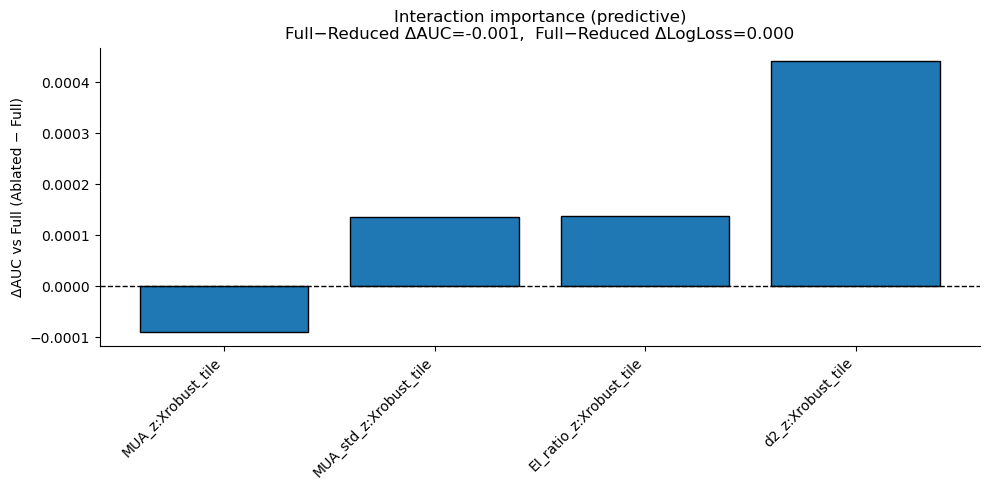

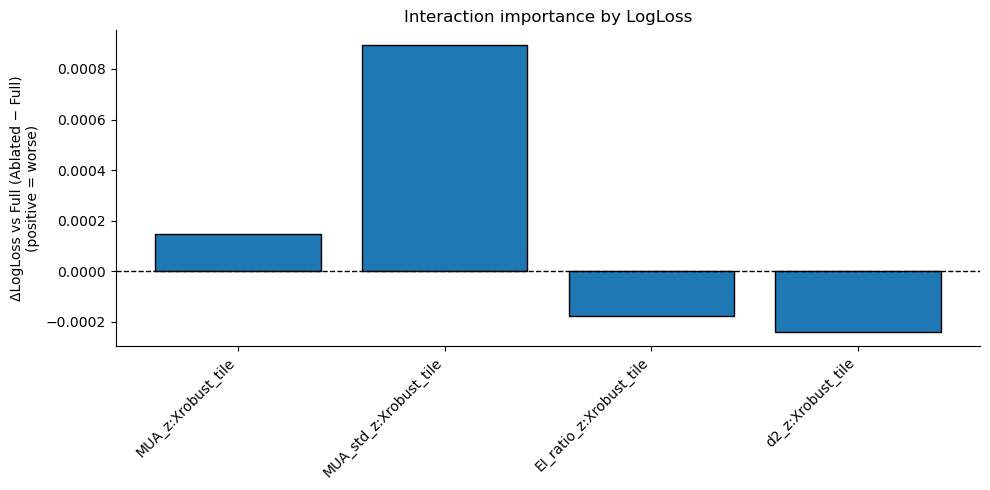

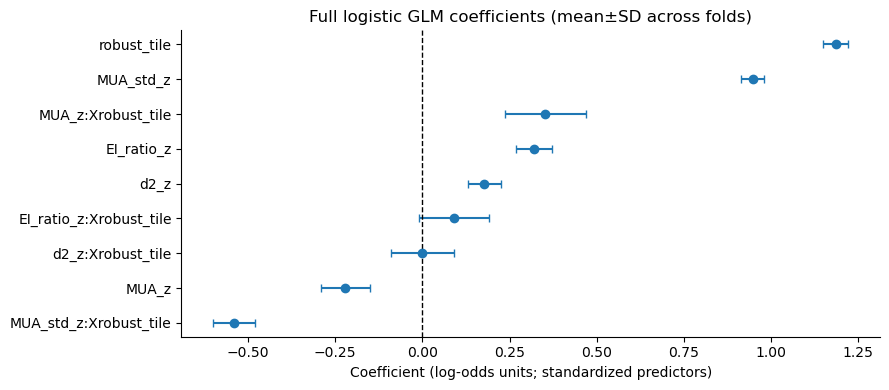

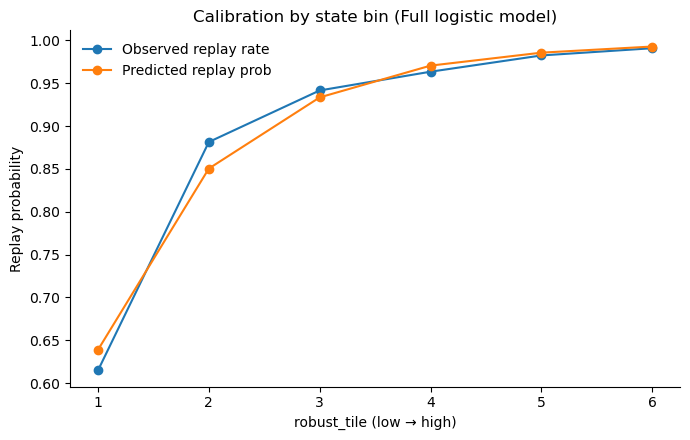

   robust_tile  obs_rate  pred_rate     n
0            1  0.614769   0.638774  1124
1            2  0.881481   0.850478  1080
2            3  0.941667   0.933569   960
3            4  0.963563   0.970667   988
4            5  0.982544   0.985792   802
5            6  0.990981   0.992957   887


In [ ]:
import numpy as np
import pandas as pd
from scipy import stats

from sklearn.model_selection import GroupKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss


# ============================================================
# 1) Your nonparametric "slope divergence" (unchanged logic, cleaner)
# ============================================================
def slope_divergence_bootstrap(
    d: pd.DataFrame,
    features=("d2", "MUA", "MUA_std", "EI_ratio"),
    tile_col="tile",
    replay_col="replay_present",
    n_bins=6,
    n_boot=1000,
    random_state=0,
    strict_require_both=True,   # require both replay & non-replay per bin
):
    """
    Computes slope of Δ(b) across bins where Δ(b) = mean(feature|replay=1,bin) - mean(feature|replay=0,bin),
    with bootstrap over rows. Returns:
      summ_df: per-feature mean slope + bootstrap SE
      raw_df:  per-bootstrap slopes
      df_work: processed dataframe with robust_tile + z-scored features
    """
    rng = np.random.default_rng(random_state)

    features = [f for f in features if f in d.columns]
    if len(features) == 0:
        raise ValueError("No requested features found in dataframe.")

    df = d.dropna(subset=[tile_col, replay_col] + features).copy()

    # robust bins
    if df[tile_col].nunique() > n_bins or df[tile_col].max() > n_bins:
        df["robust_tile"] = pd.qcut(df[tile_col], q=n_bins, labels=False, duplicates="drop")
    else:
        df["robust_tile"] = df[tile_col].astype(int)

    # z-score features (global; if you want within-session, do it before calling)
    for f in features:
        mu = df[f].mean()
        sd = df[f].std(ddof=1)
        df[f"{f}_z"] = (df[f] - mu) / (sd if sd > 0 else 1.0)

    bins = np.sort(df["robust_tile"].unique())
    boot_slopes = {f: [] for f in features}

    for bi in range(n_boot):
        sample = df.sample(frac=1.0, replace=True, random_state=int(rng.integers(0, 1e9)))
        grouped = sample.groupby(["robust_tile", replay_col])[[f"{f}_z" for f in features]].mean()

        for f in features:
            deltas, x = [], []
            for b in bins:
                # require replay=1
                if (b, 1) not in grouped.index:
                    continue
                # require replay=0 if strict
                if strict_require_both and (b, 0) not in grouped.index:
                    continue

                val_in = grouped.loc[(b, 1), f"{f}_z"]
                if (b, 0) in grouped.index:
                    val_out = grouped.loc[(b, 0), f"{f}_z"]
                else:
                    # fallback anchor (if you allow it)
                    val_out = 0.0

                deltas.append(val_in - val_out)
                x.append(b)

            if len(deltas) >= 2:
                slope, *_ = stats.linregress(x, deltas)
                boot_slopes[f].append(slope)
            else:
                boot_slopes[f].append(np.nan)

    raw_rows = []
    summ_rows = []
    for f in features:
        slopes = np.asarray(boot_slopes[f], float)
        slopes = slopes[np.isfinite(slopes)]
        raw_rows.extend([{"Feature": f, "Slope": s} for s in slopes])

        if len(slopes) == 0:
            mean_slope, se = np.nan, np.nan
            n_ok = 0
        else:
            mean_slope = slopes.mean()
            se = slopes.std(ddof=1)  # bootstrap SE
            n_ok = len(slopes)

        summ_rows.append({"Feature": f, "Mean_Slope": mean_slope, "Boot_SE": se, "N_Valid_Boot": n_ok})

    summ_df = pd.DataFrame(summ_rows).sort_values("Feature")
    raw_df = pd.DataFrame(raw_rows)

    return summ_df, raw_df, df


# ============================================================
# 2) Predictive GLM (logistic regression) + ablation gain
#    Predict replay_present from features + (feature × state-bin) interactions
# ============================================================
def _build_design(df, features, state_col="robust_tile", add_interactions=True):
    """
    Returns X matrix and column names.
    Interactions are feature_z * state (state treated numeric).
    """
    cols = []
    X_list = []

    # state
    s = df[state_col].astype(float).to_numpy().reshape(-1, 1)
    X_list.append(s)
    cols.append(state_col)

    # main effects
    for f in features:
        z = df[f"{f}_z"].to_numpy().reshape(-1, 1)
        X_list.append(z)
        cols.append(f"{f}_z")

    # interactions
    if add_interactions:
        for f in features:
            z = df[f"{f}_z"].to_numpy().reshape(-1, 1)
            X_list.append(z * s)
            cols.append(f"{f}_z:X{state_col}")

    X = np.hstack(X_list)
    return X, cols


def cv_predictive_gain_logistic(
    d: pd.DataFrame,
    features=("d2", "MUA", "MUA_std", "EI_ratio"),
    tile_col="tile",
    replay_col="replay_present",
    n_bins=6,
    group_col=None,       # e.g. "session" or "file" if you have it
    n_splits=5,
    C=1.0,                # inverse regularization strength (bigger = less reg)
    random_state=0,
):
    """
    Cross-validated predictive performance for:
      - reduced model: main effects only (state + features)
      - full model:    main + interactions (feature × state)
    Plus ablation: drop each interaction term one-at-a-time from the full model.

    Returns:
      results_df (summary), details (dict with fold-wise metrics)
    """
    # ---------- preprocess (same robust tiles + zscores) ----------
    summ_df, raw_df, df = slope_divergence_bootstrap(
        d, features=features, tile_col=tile_col, replay_col=replay_col, n_bins=n_bins,
        n_boot=50,  # quick sanity; not used for prediction; bump if you want
        random_state=random_state,
        strict_require_both=False
    )
    # keep only usable rows
    features = [f for f in features if f in df.columns]
    df = df.dropna(subset=[replay_col, "robust_tile"] + [f"{f}_z" for f in features]).copy()

    y = df[replay_col].astype(int).to_numpy()

    # grouping / splits
    if group_col is not None and group_col in df.columns:
        groups = df[group_col].to_numpy()
        splitter = GroupKFold(n_splits=n_splits)
        splits = list(splitter.split(df, y, groups=groups))
    else:
        splitter = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
        splits = list(splitter.split(df, y))

    # models
    # Use liblinear for smaller datasets; saga works too.
    def fit_eval(X, y, splits):
        aucs, lls = [], []
        for tr, te in splits:
            Xtr, Xte = X[tr], X[te]
            ytr, yte = y[tr], y[te]

            # standardize predictors *within fold* for clean CV
            sc = StandardScaler(with_mean=True, with_std=True)
            Xtr_s = sc.fit_transform(Xtr)
            Xte_s = sc.transform(Xte)

            clf = LogisticRegression(
                penalty="l2",
                C=C,
                solver="liblinear",
                max_iter=2000,
                random_state=random_state
            )
            clf.fit(Xtr_s, ytr)
            p = clf.predict_proba(Xte_s)[:, 1]

            aucs.append(roc_auc_score(yte, p))
            lls.append(log_loss(yte, p, labels=[0, 1]))

        return np.array(aucs), np.array(lls)

    # ---------- Reduced model (no interactions) ----------
    X_red, red_cols = _build_design(df, features, state_col="robust_tile", add_interactions=False)
    auc_red, ll_red = fit_eval(X_red, y, splits)

    # ---------- Full model (with interactions) ----------
    X_full, full_cols = _build_design(df, features, state_col="robust_tile", add_interactions=True)
    auc_full, ll_full = fit_eval(X_full, y, splits)

    # predictive gain (higher AUC better; lower logloss better)
    gain_auc = auc_full.mean() - auc_red.mean()
    gain_ll  = ll_red.mean() - ll_full.mean()

    rows = [{
        "Model": "Reduced (main effects)",
        "AUC_mean": auc_red.mean(), "AUC_sd": auc_red.std(ddof=1),
        "LogLoss_mean": ll_red.mean(), "LogLoss_sd": ll_red.std(ddof=1),
        "n": len(df)
    },{
        "Model": "Full (main + interactions)",
        "AUC_mean": auc_full.mean(), "AUC_sd": auc_full.std(ddof=1),
        "LogLoss_mean": ll_full.mean(), "LogLoss_sd": ll_full.std(ddof=1),
        "n": len(df)
    },{
        "Model": "Gain (Full - Reduced)",
        "AUC_mean": gain_auc, "AUC_sd": np.nan,
        "LogLoss_mean": gain_ll, "LogLoss_sd": np.nan,
        "n": len(df)
    }]

    # ---------- Ablate each interaction one-at-a-time ----------
    # Identify interaction columns in full design
    inter_idx = [i for i, c in enumerate(full_cols) if ":Xrobust_tile" in c]
    base_auc, base_ll = auc_full.mean(), ll_full.mean()

    for idx in inter_idx:
        keep = [i for i in range(X_full.shape[1]) if i != idx]
        X_ab = X_full[:, keep]
        auc_ab, ll_ab = fit_eval(X_ab, y, splits)

        rows.append({
            "Model": f"Ablate {full_cols[idx]}",
            "AUC_mean": auc_ab.mean(), "AUC_sd": auc_ab.std(ddof=1),
            "LogLoss_mean": ll_ab.mean(), "LogLoss_sd": ll_ab.std(ddof=1),
            "ΔAUC_vs_Full": auc_ab.mean() - base_auc,
            "ΔLogLoss_vs_Full": ll_ab.mean() - base_ll,
            "n": len(df)
        })

    results_df = pd.DataFrame(rows)

    details = {
        "slope_divergence_summary_quick": summ_df,   # quick check only
        "reduced": {"cols": red_cols, "auc": auc_red, "logloss": ll_red},
        "full":    {"cols": full_cols, "auc": auc_full, "logloss": ll_full},
        "splits": splits,
        "df_used": df
    }
    return results_df, details


# ============================================================
# 3) Example usage
# ============================================================
# If you have session/file ID, pass it as group_col to avoid leakage.
# e.g., group_col="file" or group_col="session"

# ---- A) Your mechanistic summary (slope divergence) ----
# summ_df, raw_df, df_work = slope_divergence_bootstrap(d, tile_col="tile", replay_col="replay_present", n_bins=6, n_boot=1000)

# ---- B) Predictive strength + ablation (GLM-ish) ----
results_df, details = cv_predictive_gain_logistic(
    d,
    features=("d2", "MUA", "MUA_std", "EI_ratio"),
    tile_col="tile",
    replay_col="replay_present",
    n_bins=6,
    group_col="session",   # set to None if you don't have it
    n_splits=5,
    C=1.0,
    random_state=0
)
# print(results_df.sort_values("Model").to_string(index=False))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss


def _despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)


def plot_glm_gain_from_results(results_df, title="Predictive gain from interactions"):
    """
    Plots Full-vs-Reduced gain and each interaction ablation's ΔAUC / ΔLogLoss vs Full.
    Expects results_df returned by cv_predictive_gain_logistic.
    """
    df = results_df.copy()

    # ---- Gain summary (Full - Reduced) ----
    gain_row = df[df["Model"] == "Gain (Full - Reduced)"]
    if len(gain_row) != 1:
        print("Could not find Gain (Full - Reduced) row. Plotting ablations only.")
        gain_auc = np.nan
        gain_ll = np.nan
    else:
        gain_auc = float(gain_row["AUC_mean"].iloc[0])
        gain_ll  = float(gain_row["LogLoss_mean"].iloc[0])

    # ---- Ablations ----
    ab = df[df["Model"].str.startswith("Ablate")].copy()
    if len(ab) == 0:
        print("No ablation rows found. Nothing to plot.")
        return

    # Sort by ΔAUC (most harmful drop first = most negative)
    if "ΔAUC_vs_Full" in ab.columns:
        ab = ab.sort_values("ΔAUC_vs_Full")

    fig, ax = plt.subplots(figsize=(10, 5))
    x = np.arange(len(ab))
    y = ab["ΔAUC_vs_Full"].to_numpy()

    ax.bar(x, y, edgecolor="k")
    ax.axhline(0, linestyle="--", linewidth=1, color="k")
    ax.set_xticks(x)
    ax.set_xticklabels(ab["Model"].str.replace("Ablate ", "", regex=False), rotation=45, ha="right")
    ax.set_ylabel("ΔAUC vs Full (Ablated − Full)")
    ax.set_title(f"{title}\nFull−Reduced ΔAUC={gain_auc:.3f},  Full−Reduced ΔLogLoss={gain_ll:.3f}")
    _despine(ax)
    plt.tight_layout()
    plt.show()

    # Optional LogLoss ablation plot
    if "ΔLogLoss_vs_Full" in ab.columns:
        fig, ax = plt.subplots(figsize=(10, 5))
        y2 = ab["ΔLogLoss_vs_Full"].to_numpy()
        ax.bar(x, y2, edgecolor="k")
        ax.axhline(0, linestyle="--", linewidth=1, color="k")
        ax.set_xticks(x)
        ax.set_xticklabels(ab["Model"].str.replace("Ablate ", "", regex=False), rotation=45, ha="right")
        ax.set_ylabel("ΔLogLoss vs Full (Ablated − Full)\n(positive = worse)")
        ax.set_title("Interaction importance by LogLoss")
        _despine(ax)
        plt.tight_layout()
        plt.show()


def fit_full_logistic_per_fold(details, C=1.0, random_state=0):
    """
    Refit FULL model on each CV fold to extract coefficients (standardized within fold).
    Returns coef_df with columns: term, fold, coef.
    """
    df = details["df_used"].copy()
    splits = details["splits"]
    full_cols = details["full"]["cols"]

    # rebuild X_full the same way as before
    # (we assume you used _build_design(df, features, add_interactions=True))
    # We'll reconstruct features from column names:
    # full_cols = ['robust_tile', 'd2_z', 'MUA_z', ..., 'd2_z:Xrobust_tile', ...]
    # so X_full can be created using those columns if they exist; but here X_full
    # is not stored. We'll re-create directly from df with _build_design.
    # Need features list: those ending with _z but not interaction
    features = [c.replace("_z", "") for c in full_cols if c.endswith("_z") and ":X" not in c]

    from sklearn.model_selection import GroupKFold, KFold  # just for namespace safety

    # Use the same builder you already have
    X_full, full_cols = _build_design(df, features, state_col="robust_tile", add_interactions=True)
    y = df["replay_present"].astype(int).to_numpy()

    coef_rows = []

    for k, (tr, te) in enumerate(splits):
        Xtr = X_full[tr]
        ytr = y[tr]

        sc = StandardScaler(with_mean=True, with_std=True)
        Xtr_s = sc.fit_transform(Xtr)

        clf = LogisticRegression(
            penalty="l2",
            C=C,
            solver="liblinear",
            max_iter=2000,
            random_state=random_state
        )
        clf.fit(Xtr_s, ytr)

        coefs = clf.coef_.ravel()
        for term, cval in zip(full_cols, coefs):
            coef_rows.append({"term": term, "fold": k, "coef": cval})

    return pd.DataFrame(coef_rows)


def plot_glm_coefficients(coef_df, title="Full model coefficients (per-fold)"):
    """
    Coefficient plot: mean ± SD across folds.
    Positive coef => increases log-odds of replay (holding others fixed).
    """
    summ = (coef_df
            .groupby("term")["coef"]
            .agg(["mean", "std"])
            .reset_index()
            .sort_values("mean"))

    fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(summ))))
    y = np.arange(len(summ))
    ax.errorbar(summ["mean"].to_numpy(), y, xerr=summ["std"].to_numpy(), fmt="o", capsize=3)
    ax.axvline(0, linestyle="--", linewidth=1, color="k")
    ax.set_yticks(y)
    ax.set_yticklabels(summ["term"])
    ax.set_xlabel("Coefficient (log-odds units; standardized predictors)")
    ax.set_title(title)
    _despine(ax)
    plt.tight_layout()
    plt.show()


def plot_predicted_replay_by_tile(details, C=1.0, random_state=0, n_bins_show=None):
    """
    Fit FULL model on all data, then plot:
      - observed replay rate per tile
      - predicted replay probability per tile (mean)
    This is a very interpretable "GLM plot" for gating.
    """
    df = details["df_used"].copy()
    full_cols = details["full"]["cols"]

    features = [c.replace("_z", "") for c in full_cols if c.endswith("_z") and ":X" not in c]
    X_full, full_cols = _build_design(df, features, state_col="robust_tile", add_interactions=True)
    y = df["replay_present"].astype(int).to_numpy()

    sc = StandardScaler(with_mean=True, with_std=True)
    Xs = sc.fit_transform(X_full)

    clf = LogisticRegression(
        penalty="l2",
        C=C,
        solver="liblinear",
        max_iter=2000,
        random_state=random_state
    )
    clf.fit(Xs, y)
    p = clf.predict_proba(Xs)[:, 1]
    df = df.copy()
    df["p_hat"] = p

    g = df.groupby("robust_tile").agg(
        obs_rate=( "replay_present", "mean"),
        pred_rate=("p_hat", "mean"),
        n=("p_hat", "size")
    ).reset_index().sort_values("robust_tile")

    if n_bins_show is not None:
        g = g.tail(n_bins_show)

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(g["robust_tile"], g["obs_rate"], marker="o", label="Observed replay rate")
    ax.plot(g["robust_tile"], g["pred_rate"], marker="o", label="Predicted replay prob")
    ax.set_xlabel("robust_tile (low → high)")
    ax.set_ylabel("Replay probability")
    ax.set_title("Calibration by state bin (Full logistic model)")
    ax.legend(frameon=False)
    _despine(ax)
    plt.tight_layout()
    plt.show()

    return g

# Plot (A) interaction importance via ablation
plot_glm_gain_from_results(results_df, title="Interaction importance (predictive)")

# Plot (B) coefficients across folds (Full model)
coef_df = fit_full_logistic_per_fold(details, C=1.0, random_state=0)
plot_glm_coefficients(coef_df, title="Full logistic GLM coefficients (mean±SD across folds)")

# Plot (C) predicted vs observed replay rate across tiles (gating visualization)
tile_calib = plot_predicted_replay_by_tile(details, C=1.0, random_state=0)
print(tile_calib)

In [ ]:
# import os

# # Ensure your output directory exists
outdir = r'D:\Documents\GitHub\Sleep_criticaltiy\data\GLM_mice\explore'
os.makedirs(outdir, exist_ok=True)


# Construct the filename
filename = f"{animal_name}_{day}_ablation_results_slope.pkl"
save_path = os.path.join(outdir, filename)

# Save the DataFrame
res.to_pickle(save_path)

print(f"Saved ablation results to: {save_path}")
Ensure your output directory exists
outdir = r'D:\Documents\GitHub\Sleep_criticaltiy\data\GLM_mice\explore'
os.makedirs(outdir, exist_ok=True)

# Define your animal and day variables if they aren't already set
# animal_name = "SuperRat"
# day = "Day1"

# Construct the filename
filename = f"{animal_name}_{day}_ablation_results_GLM.pkl"
save_path = os.path.join(outdir, filename)
# Construct a consolidated save object
save_data = {
    "summary": results_df,
    "slopes": details["slope_divergence_summary_quick"], # The "Divergence Slopes"
    "auc_folds": {
        "full": details["full"]["auc"],
        "reduced": details["reduced"]["auc"]
    },
    "n_samples": len(details["df_used"]),
    "animal": animal_name,
    "day": day
}

# Save it
save_path = os.path.join(outdir, f"{animal_name}_{day}_ablation_results_GLM.pkl")
# # Save the DataFrame
pd.to_pickle(save_data, save_path)

# print(f"Saved ablation results to: {save_path}")
# # Construct the filename
# filename = f"{animal_name}_{day}_ablation_results_d.pkl"
# save_path = os.path.join(outdir, filename)

# # Save the DataFrame
# d.to_pickle(save_path)

# print(f"Saved ablation results to: {save_path}")
# Plot (A) interaction importance via ablation

Skip (unexpected format): D:\Documents\GitHub\Sleep_criticaltiy\data\GLM_mice\PPP8_day8_ablation_results_GLM.pkl
Loaded 9 GLM pkls
Pooled shape: (56, 12)
Ablation rows: (32, 13)
Gain rows: (24, 12)


C:\Users\Cornell\AppData\Local\Temp\ipykernel_68804\843226616.py:102: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.


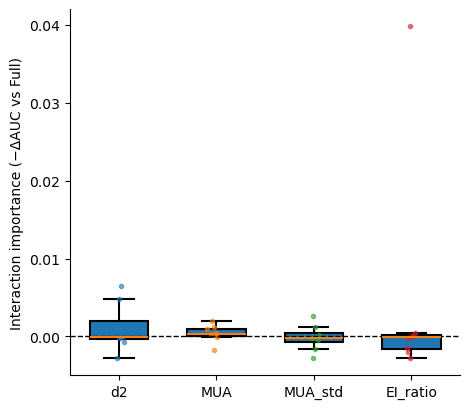

Saved: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\Fig_GLM_boxplot_interaction_importance_AUC.svg


C:\Users\Cornell\AppData\Local\Temp\ipykernel_68804\843226616.py:102: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.


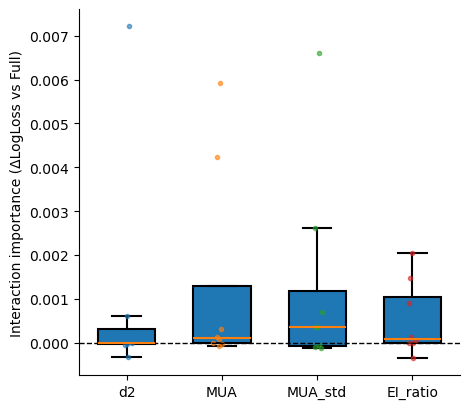

C:\Users\Cornell\AppData\Local\Temp\ipykernel_68804\843226616.py:217: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.


Saved: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\Fig_GLM_boxplot_interaction_importance_LogLoss.svg


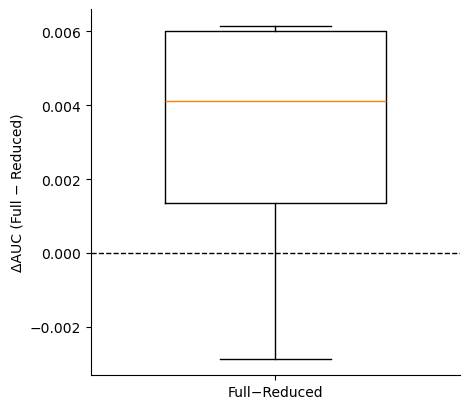

Saved: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\Fig_GLM_boxplot_full_minus_reduced_AUC_gain.svg


In [ ]:
import os, glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------
# Settings
# ---------------------------
indir  = r"D:\Documents\GitHub\Sleep_criticaltiy\data\GLM_mice"
outdir = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan"
os.makedirs(outdir, exist_ok=True)

FEATURES_KEEP = ["d2", "MUA", "MUA_std","EI_ratio"]  # adjust if you also saved EI_ratio etc.

# ---------------------------
# Helpers
# ---------------------------
def _despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)

def parse_animal_day_from_filename(fp):
    base = os.path.basename(fp)
    m = re.match(r"(.+?)_(.+?)_ablation_results_GLM\.pkl$", base)
    return (m.group(1), m.group(2)) if m else (None, None)

def extract_ablation_feature(model_name):
    """
    Expected model_name like:
      'Ablate d2_z:Xrobust_tile'
      'Ablate MUA_z:Xrobust_tile'
    Returns: 'd2', 'MUA', 'MUA_std' etc.
    """
    s = model_name.replace("Ablate ", "")
    # take left side before '_z'
    if "_z" in s:
        return s.split("_z")[0]
    return s

def load_and_pool_glm_pickles(indir):
    """
    Loads every *_ablation_results_GLM.pkl created by:
      save_data = {"summary": results_df, ...}
    Returns:
      pooled_summary_df (long, one row per model per file)
      pooled_ablation_df (only ablation rows, with Feature parsed)
      pooled_gain_df (Full/Reduced/Gain rows)
    """
    files = sorted(glob.glob(os.path.join(indir, "*_ablation_results_GLM.pkl")))
    if len(files) == 0:
        raise FileNotFoundError(f"No *_ablation_results_GLM.pkl found in: {indir}")

    all_rows = []
    for fp in files:
        obj = pd.read_pickle(fp)  # dict
        if not isinstance(obj, dict) or "summary" not in obj:
            print(f"Skip (unexpected format): {fp}")
            continue

        df = obj["summary"].copy()
        df["file"] = os.path.basename(fp)

        # Prefer embedded animal/day if present, otherwise parse from filename
        animal = obj.get("animal", None)
        day = obj.get("day", None)
        if animal is None or day is None:
            animal2, day2 = parse_animal_day_from_filename(fp)
            animal = animal if animal is not None else animal2
            day = day if day is not None else day2

        df["animal"] = animal
        df["day"] = day
        df["n_samples"] = obj.get("n_samples", np.nan)

        all_rows.append(df)

    pooled = pd.concat(all_rows, ignore_index=True)

    # Split into sections
    ab = pooled[pooled["Model"].str.startswith("Ablate")].copy()
    ab["Feature"] = ab["Model"].apply(extract_ablation_feature)
    ab = ab[ab["Feature"].isin(FEATURES_KEEP)].copy()

    gain = pooled[pooled["Model"].isin([
        "Reduced (main effects)",
        "Full (main + interactions)",
        "Gain (Full - Reduced)"
    ])].copy()

    return pooled, ab, gain, files

def make_boxplot_matplotlib(df, value_col, title, ylabel, save_path, order=None, show_points=True):
    """
    Simple matplotlib boxplot (no seaborn).
    """
    if order is None:
        order = sorted(df["Feature"].unique())

    data = [df.loc[df["Feature"] == f, value_col].dropna().values for f in order]
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    bp = ax.boxplot(data, labels=order, showfliers=False, widths=0.6, patch_artist=True)

    # style
    for patch in bp["boxes"]:
        patch.set_linewidth(1.5)
    for k in ["whiskers", "caps", "medians"]:
        for line in bp[k]:
            line.set_linewidth(1.5)

    # optional jitter points
    if show_points:
        rng = np.random.default_rng(0)
        for i, f in enumerate(order, start=1):
            y = df.loc[df["Feature"] == f, value_col].dropna().values
            if len(y) == 0:
                continue
            x = i + rng.normal(0, 0.04, size=len(y))
            ax.plot(x, y, "o", markersize=3, alpha=0.6)

    ax.axhline(0, linestyle="--", linewidth=1, color="k")
    ax.set_title(title if title else "")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("")
    _despine(ax)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()
    plt.close()
    print(f"Saved: {save_path}")

def make_bar_mean_sem(df, value_col, title, ylabel, save_path, order=None):
    """
    Bar plot mean ± SEM across files.
    """
    if order is None:
        order = sorted(df["Feature"].unique())

    g = df.groupby("Feature")[value_col].agg(["mean", "std", "count"]).reindex(order)
    sem = g["std"] / np.sqrt(np.maximum(g["count"].values, 1))

    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    x = np.arange(len(order))
    ax.bar(x, g["mean"].values, yerr=sem.values, capsize=5, edgecolor="k")
    ax.set_xticks(x)
    ax.set_xticklabels(order)
    ax.axhline(0, linestyle="--", linewidth=1, color="k")
    ax.set_title(title if title else "")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("")
    _despine(ax)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()
    plt.close()
    print(f"Saved: {save_path}")

# ---------------------------
# Load + pool
# ---------------------------
pooled, ab_df, gain_df, glm_files = load_and_pool_glm_pickles(indir)
print(f"Loaded {len(glm_files)} GLM pkls")
print("Pooled shape:", pooled.shape)
print("Ablation rows:", ab_df.shape)
print("Gain rows:", gain_df.shape)

# ---------------------------
# Decide what to plot
# ---------------------------
# In your cv code:
#  - ΔAUC_vs_Full < 0 means removing that interaction hurts performance (important interaction)
#  - ΔLogLoss_vs_Full > 0 means removing hurts performance
#
# So for “importance magnitude”, a clean directionless score is:
#   Importance_AUC = -ΔAUC_vs_Full  (bigger = more important)
#   Importance_LL  =  ΔLogLoss_vs_Full (bigger = more important)
ab_df["Importance_AUC"] = -ab_df["ΔAUC_vs_Full"]
ab_df["Importance_LL"]  =  ab_df["ΔLogLoss_vs_Full"]

# ---------------------------
# (1) Boxplot of interaction importance (AUC)
# ---------------------------
make_boxplot_matplotlib(
    ab_df,
    value_col="Importance_AUC",
    title=None,
    ylabel="Interaction importance (−ΔAUC vs Full)",
    save_path=os.path.join(outdir, "Fig_GLM_boxplot_interaction_importance_AUC.svg"),
    order=[f for f in FEATURES_KEEP if f in ab_df["Feature"].unique()],
    show_points=True
)

# ---------------------------
# (2) Bar plot mean±SEM of interaction importance (AUC)
# ---------------------------
# ---------------------------
# (3) Optional: Boxplot for LogLoss importance
# ---------------------------
make_boxplot_matplotlib(
    ab_df,
    value_col="Importance_LL",
    title=None,
    ylabel="Interaction importance (ΔLogLoss vs Full)",
    save_path=os.path.join(outdir, "Fig_GLM_boxplot_interaction_importance_LogLoss.svg"),
    order=[f for f in FEATURES_KEEP if f in ab_df["Feature"].unique()],
    show_points=True
)

# ---------------------------
# (4) Optional: Full vs Reduced gain across files (single distribution)
# ---------------------------
gain_row = pooled[pooled["Model"] == "Gain (Full - Reduced)"].copy()
if not gain_row.empty:
    # Each file should have one "Gain" row; plot its AUC gain distribution
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    vals = gain_row["AUC_mean"].dropna().values
    ax.boxplot([vals], labels=["Full−Reduced"], showfliers=False, widths=0.6)
    ax.axhline(0, linestyle="--", linewidth=1, color="k")
    ax.set_ylabel("ΔAUC (Full − Reduced)")
    _despine(ax)
    plt.tight_layout()
    save_path = os.path.join(outdir, "Fig_GLM_boxplot_full_minus_reduced_AUC_gain.svg")
    plt.savefig(save_path, dpi=300)
    plt.show()
    plt.close()
    print(f"Saved: {save_path}")
else:
    print("No Gain (Full - Reduced) rows found—did you include that row in results_df?")


In [ ]:
pooled 

,Model,AUC_mean,AUC_sd,LogLoss_mean,LogLoss_sd,n,ΔAUC_vs_Full,ΔLogLoss_vs_Full,file,animal,day,n_samples
0,Reduced (main effects),0.957254,0.011280,0.053512,0.011055,5424,NaN,NaN,PPP20_day4_ablation_results_GLM.pkl,PPP20,day4,5424
1,Full (main + interactions),0.963412,0.009589,0.052666,0.010948,5424,NaN,NaN,PPP20_day4_ablation_results_GLM.pkl,PPP20,day4,5424
2,Gain (Full - Reduced),0.006158,NaN,0.000845,NaN,5424,NaN,NaN,PPP20_day4_ablation_results_GLM.pkl,PPP20,day4,5424
3,Ablate d2_z:Xrobust_tile,0.958597,0.009001,0.053276,0.010773,5424,-0.004815,0.000609,PPP20_day4_ablation_results_GLM.pkl,PPP20,day4,5424
4,Ablate MUA_z:Xrobust_tile,0.962251,0.010327,0.052760,0.011027,5424,-0.001161,0.000094,PPP20_day4_ablation_results_GLM.pkl,PPP20,day4,5424
5,Ablate MUA_std_z:Xrobust_tile,0.963653,0.009941,0.052568,0.011006,5424,0.000242,-0.000098,PPP20_day4_ablation_results_GLM.pkl,PPP20,day4,5424
6,Ablate EI_ratio_z:Xrobust_tile,0.962965,0.009625,0.052716,0.010916,5424,-0.000447,0.000049,PPP20_day4_ablation_results_GLM.pkl,PPP20,day4,5424
7,Reduced (main effects),0.947246,0.015590,0.076724,0.013987,5841,NaN,NaN,PPP20_day5_ablation_results_GLM.pkl,PPP20,day5,5841
8,Full (main + interactions),0.950780,0.013937,0.075919,0.013578,5841,NaN,NaN,PPP20_day5_ablation_results_GLM.pkl,PPP20,day5,5841
9,Gain (Full - Reduced),0.003534,NaN,0.000805,NaN,5841,NaN,NaN,PPP20_day5_ablation_results_GLM.pkl,PPP20,day5,5841


Loaded 9 GLM pkls
Pooled shape: (56, 12)

--- Statistics for Gain in AUC (Full - Ablated) ---
  d2         | Mean: 0.00106 | Median: -0.00002 | p-val (vs 0): 3.7e-01
  MUA        | Mean: 0.00039 | Median: 0.00034 | p-val (vs 0): 9.8e-02
  MUA_std    | Mean: -0.00015 | Median: -0.00025 | p-val (vs 0): 7.7e-01
  EI_ratio   | Mean: 0.00423 | Median: -0.00011 | p-val (vs 0): 7.7e-01


C:\Users\Cornell\AppData\Local\Temp\ipykernel_68804\2577084693.py:61: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.


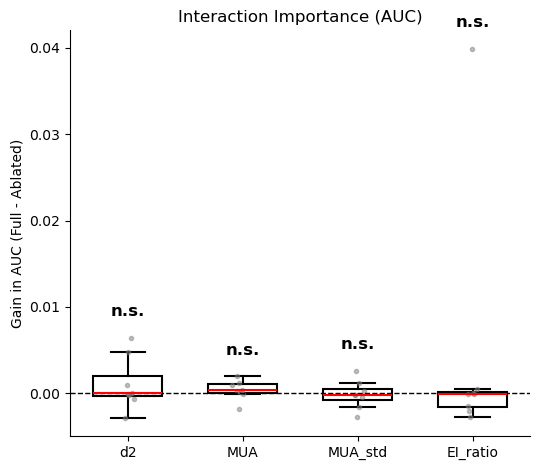

Saved: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\Fig_GLM_boxplot_interaction_importance_AUC.svg


C:\Users\Cornell\AppData\Local\Temp\ipykernel_68804\2577084693.py:61: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.



--- Statistics for Gain in LogLoss (Full - Ablated) ---
  d2         | Mean: 0.00095 | Median: -0.00000 | p-val (vs 0): 3.7e-01
  MUA        | Mean: 0.00132 | Median: 0.00011 | p-val (vs 0): 5.5e-02
  MUA_std    | Mean: 0.00130 | Median: 0.00036 | p-val (vs 0): 5.5e-02
  EI_ratio   | Mean: 0.00053 | Median: 0.00008 | p-val (vs 0): 9.8e-02


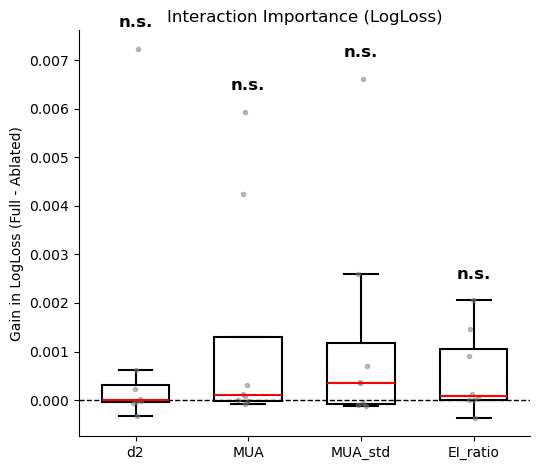

Saved: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\Fig_GLM_boxplot_interaction_importance_LogLoss.svg

--- Comparative Statistics (Kruskal-Wallis) ---
Kruskal-Wallis Test (Are features different?): H=2.05, p=0.5613

PAIRWISE COMPARISONS (Importance_AUC)
Comparison           | Winner     | Diff     | P-Value    | Sig
-----------------------------------------------------------------
MUA vs EI_ratio      | EI_ratio   | 0.0038   | 2.0e-01    | ns
MUA vs MUA_std       | MUA        | 0.0005   | 4.6e-01    | ns
d2 vs MUA_std        | d2         | 0.0012   | 5.5e-01    | ns
d2 vs EI_ratio       | EI_ratio   | 0.0032   | 5.5e-01    | ns
d2 vs MUA            | d2         | 0.0007   | 7.4e-01    | ns
MUA_std vs EI_ratio  | EI_ratio   | 0.0044   | 7.4e-01    | ns


In [ ]:
import os, glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats  # <--- Added for statistics

# ---------------------------
# Settings
# ---------------------------
indir  = r"D:\Documents\GitHub\Sleep_criticaltiy\data\GLM_mice"
outdir = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan"
os.makedirs(outdir, exist_ok=True)

FEATURES_KEEP = ["d2", "MUA", "MUA_std","EI_ratio"]  # adjust if you also saved EI_ratio etc.

# ---------------------------
# Helpers
# ---------------------------
def _despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)

def parse_animal_day_from_filename(fp):
    base = os.path.basename(fp)
    m = re.match(r"(.+?)_(.+?)_ablation_results_GLM\.pkl$", base)
    return (m.group(1), m.group(2)) if m else (None, None)

def extract_ablation_feature(model_name):
    s = model_name.replace("Ablate ", "")
    if "_z" in s:
        return s.split("_z")[0]
    return s

def get_star_string(p):
    """Returns significance stars based on p-value."""
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'n.s.'

# ---------------------------
# UPDATED PLOTTING FUNCTION
# ---------------------------
def make_boxplot_matplotlib(df, value_col, title, ylabel, save_path, order=None, show_points=True):
    """
    Standard matplotlib boxplot with Wilcoxon Signed-Rank Test annotations.
    """
    if order is None:
        order = sorted(df["Feature"].unique())

    # Prepare data list for boxplot
    data_list = []
    for f in order:
        vals = df.loc[df["Feature"] == f, value_col].dropna().values
        data_list.append(vals)

    fig, ax = plt.subplots(figsize=(5.5, 4.8)) # Slightly wider for stats text
    
    # Draw boxplot
    bp = ax.boxplot(data_list, labels=order, showfliers=False, widths=0.6, patch_artist=True)

    # Style boxes
    for patch in bp["boxes"]:
        patch.set_facecolor('white')
        patch.set_linewidth(1.5)
    for k in ["whiskers", "caps", "medians"]:
        for line in bp[k]:
            line.set_linewidth(1.5)
            if k == "medians": line.set_color('red')

    # Add jitter points
    if show_points:
        rng = np.random.default_rng(0)
        for i, vals in enumerate(data_list, start=1):
            if len(vals) == 0: continue
            x = i + rng.normal(0, 0.04, size=len(vals))
            ax.plot(x, vals, "o", markersize=3, alpha=0.5, color='gray')

    # -------------------------------------------------------
    # STATISTICS & ANNOTATION
    # -------------------------------------------------------
    print(f"\n--- Statistics for {ylabel} ---")
    y_max_limit = -np.inf
    
    for i, (feature, vals) in enumerate(zip(order, data_list), start=1):
        if len(vals) < 2:
            print(f"  {feature}: Not enough data for test (n={len(vals)})")
            continue
        
        # Test: Is the distribution significantly greater than 0?
        # Wilcoxon Signed-Rank Test is appropriate for "paired" diffs (Full - Reduced)
        try:
            stat, pval = stats.wilcoxon(vals, alternative='greater')
        except ValueError:
            # Fallback if all values are identical (e.g. all 0)
            pval = 1.0

        print(f"  {feature:10s} | Mean: {np.mean(vals):.5f} | Median: {np.median(vals):.5f} | p-val (vs 0): {pval:.1e}")

        # Add stars to plot
        stars = get_star_string(pval)
        
        # Calculate position for the star (above the highest point or whisker)
        if len(vals) > 0:
            top_val = np.max(vals)
            # Add a small buffer based on data range
            y_range = (np.max(np.concatenate(data_list)) - np.min(np.concatenate(data_list)))
            text_y = top_val + (y_range * 0.05)
            
            ax.text(i, text_y, stars, ha='center', va='bottom', fontsize=12, fontweight='bold')
            
            # Track max y for axis scaling
            if text_y > y_max_limit:
                y_max_limit = text_y

    # Adjust Y-axis to fit stars
    current_ylim = ax.get_ylim()
    if y_max_limit > current_ylim[1]:
        ax.set_ylim(current_ylim[0], y_max_limit + (y_max_limit * 0.05))

    ax.axhline(0, linestyle="--", linewidth=1, color="k")
    ax.set_title(title if title else "")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("")
    _despine(ax)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()
    plt.close()
    print(f"Saved: {save_path}")

# ---------------------------
# Load + pool
# ---------------------------
def load_and_pool_glm_pickles(indir):
    files = sorted(glob.glob(os.path.join(indir, "*_ablation_results_GLM.pkl")))
    if len(files) == 0:
        raise FileNotFoundError(f"No *_ablation_results_GLM.pkl found in: {indir}")

    all_rows = []
    for fp in files:
        obj = pd.read_pickle(fp)
        if not isinstance(obj, dict) or "summary" not in obj:
            continue

        df = obj["summary"].copy()
        df["file"] = os.path.basename(fp)
        
        # Metadata extraction
        animal = obj.get("animal", None)
        day = obj.get("day", None)
        if animal is None or day is None:
            animal2, day2 = parse_animal_day_from_filename(fp)
            animal = animal if animal is not None else animal2
            day = day if day is not None else day2

        df["animal"] = animal
        df["day"] = day
        df["n_samples"] = obj.get("n_samples", np.nan)
        all_rows.append(df)

    pooled = pd.concat(all_rows, ignore_index=True)

    # Process Data
    ab = pooled[pooled["Model"].str.startswith("Ablate")].copy()
    ab["Feature"] = ab["Model"].apply(extract_ablation_feature)
    ab = ab[ab["Feature"].isin(FEATURES_KEEP)].copy()
    
    # Calculate Importance Metrics
    # (Positive value = Interaction helped)
    ab["Importance_AUC"] = -ab["ΔAUC_vs_Full"]
    ab["Importance_LL"]  =  ab["ΔLogLoss_vs_Full"]

    gain = pooled[pooled["Model"].isin(["Reduced (main effects)", "Full (main + interactions)", "Gain (Full - Reduced)"])].copy()

    return pooled, ab, gain, files

# ---------------------------
# MAIN EXECUTION
# ---------------------------
pooled, ab_df, gain_df, glm_files = load_and_pool_glm_pickles(indir)

print(f"Loaded {len(glm_files)} GLM pkls")
print("Pooled shape:", pooled.shape)

# 1. Boxplot + Stats for AUC Importance
make_boxplot_matplotlib(
    ab_df,
    value_col="Importance_AUC",
    title="Interaction Importance (AUC)",
    ylabel="Gain in AUC (Full - Ablated)",
    save_path=os.path.join(outdir, "Fig_GLM_boxplot_interaction_importance_AUC.svg"),
    order=[f for f in FEATURES_KEEP if f in ab_df["Feature"].unique()],
    show_points=True
)

# 2. Boxplot + Stats for LogLoss Importance
make_boxplot_matplotlib(
    ab_df,
    value_col="Importance_LL",
    title="Interaction Importance (LogLoss)",
    ylabel="Gain in LogLoss (Full - Ablated)",
    save_path=os.path.join(outdir, "Fig_GLM_boxplot_interaction_importance_LogLoss.svg"),
    order=[f for f in FEATURES_KEEP if f in ab_df["Feature"].unique()],
    show_points=True
)

# 3. Overall ANOVA (Kruskal-Wallis) to see if features differ from each other
print("\n--- Comparative Statistics (Kruskal-Wallis) ---")
try:
    groups = []
    group_names = []
    for f in FEATURES_KEEP:
        if f in ab_df["Feature"].unique():
            vals = ab_df.loc[ab_df["Feature"] == f, "Importance_AUC"].dropna().values
            groups.append(vals)
            group_names.append(f)
    
    if len(groups) > 1:
        stat, pval = stats.kruskal(*groups)
        print(f"Kruskal-Wallis Test (Are features different?): H={stat:.2f}, p={pval:.4f}")
        if pval < 0.05:
            print("  -> Significant difference between features.")
    else:
        print("Not enough groups for Kruskal-Wallis.")
except Exception as e:
    print(f"Error in comparative stats: {e}")
    import itertools

import itertools

def perform_pairwise_comparisons(df, value_col, features):
    """
    Performs pairwise Wilcoxon Signed-Rank tests between features.
    Matches data by 'file' to ensure paired testing (same session).
    """
    print(f"\n{'='*20}\nPAIRWISE COMPARISONS ({value_col})\n{'='*20}")
    
    # 1. Pivot to ensure we compare the EXACT same sessions
    #    Rows = Files, Columns = Features
    pivoted = df.pivot(index='file', columns='Feature', values=value_col)
    
    # 2. Get all unique pairs of features
    pairs = list(itertools.combinations(features, 2))
    
    results = []
    
    for f1, f2 in pairs:
        # Get data for both features, dropping any sessions where one might be missing
        subset = pivoted[[f1, f2]].dropna()
        n = len(subset)
        
        if n < 2:
            print(f"{f1} vs {f2}: Not enough paired data (n={n})")
            continue
            
        # Paired test
        stat, pval = stats.wilcoxon(subset[f1], subset[f2])
        
        # Calculate mean difference
        mean_diff = subset[f1].mean() - subset[f2].mean()
        winner = f1 if mean_diff > 0 else f2
        
        results.append({
            "Comparison": f"{f1} vs {f2}",
            "Winner": winner,
            "Mean_Diff": abs(mean_diff),
            "p_value": pval,
            "n": n
        })

    # 3. Create DataFrame and sort by significance
    res_df = pd.DataFrame(results).sort_values("p_value")
    
    # 4. Display
    print(f"{'Comparison':<20} | {'Winner':<10} | {'Diff':<8} | {'P-Value':<10} | {'Sig'}")
    print("-" * 65)
    for _, row in res_df.iterrows():
        p = row['p_value']
        sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
        print(f"{row['Comparison']:<20} | {row['Winner']:<10} | {row['Mean_Diff']:.4f}   | {p:.1e}    | {sig}")
        
    return res_df

# --- EXECUTE ---
# Run this on your AUC importance data
pairwise_stats = perform_pairwise_comparisons(ab_df, "Importance_AUC", FEATURES_KEEP)